<div style="border: 5px solid black; padding: 20px; border-radius: 6px;">


## **Name:** Tim Hollis
## **Project:** Priced Out of Equity: Home Valuation Gaps in Historically Black Neighborhoods

---

**Reference**

Federal Housing Finance Agency. (2024). *Uniform Appraisal Dataset (UAD) aggregate statistics* [Data set]. https://www.fhfa.gov/data/uad

Federal Housing Finance Agency. (2025). *Uniform Appraisal Dataset (UAD) appraisal-level public use file* (Version 2.1) [Data set]. https://www.fhfa.gov/data/uad/puf

Meier, H. C. S., & Mitchell, B. C. (2023). *Historic redlining indicator for 2000, 2010, and 2020 US census tracts* (Version 3) [Data set]. Inter-university Consortium for Political and Social Research. https://doi.org/10.3886/E141121V3

U.S. Census Bureau. (2024). *2019–2023 American Community Survey 5-year estimates* [Data set]. https://www.census.gov/programs-surveys/acs

</div>

### **Initial Setup**

The setup cell below gathers everything the rest of the notebook depends on: library imports, file paths, analysis settings, chart formatting, and data loading. Two choices in it are worth explaining up front.

First, the FHFA tract file is too large to read comfortably with pandas, so on the first run the cell streams it out of its zip archive into a compressed Parquet file in `Data/Processed`. DuckDB then queries that file directly, so the notebook only pulls into memory the slices each step needs. Later runs skip the conversion and start in seconds.

Second, `POOL_YEARS` combines appraisals from 2019 through 2023. A single year leaves too many tracts suppressed for low volume, and these five years line up exactly with the 2019 to 2023 American Community Survey estimates used for neighborhood characteristics, so both sides of every comparison describe the same period.

In [1]:
# Imports
import io
import os
import warnings
import zipfile
from pathlib import Path

import duckdb
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.csv as pacsv
import pyarrow.parquet as pq
import requests
import shap
import statsmodels.api as sm
import statsmodels.formula.api as smf
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, MaxNLocator
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold

warnings.filterwarnings('ignore', category=FutureWarning)

# Paths
PROJECT_DIR = Path.cwd()
RAW_DIR = PROJECT_DIR / 'Data' / 'Raw'
PROCESSED_DIR = PROJECT_DIR / 'Data' / 'Processed'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

UAD_TRACT_ZIP = RAW_DIR / 'UADAggs_ent_sf_tract_v3_3.zip'
HRI_ZIP = RAW_DIR / 'ICPSR_141121-V3.6.zip'
UAD_TRACT_PARQUET = PROCESSED_DIR / 'uad_ent_sf_tract.parquet'

ACS_YEAR = 2023
ACS_PARQUET = PROCESSED_DIR / f'acs_{ACS_YEAR - 4}_{ACS_YEAR}_tract.parquet'
CBSA_FILE = RAW_DIR / 'list1_2023.xlsx'
ACS_VARIABLES = {
    'B03002_001E': 'pop_total',
    'B03002_003E': 'pop_white_nh',
    'B03002_004E': 'pop_black_nh',
    'B03002_012E': 'pop_hispanic',
    'B25018_001E': 'median_rooms',
    'B25035_001E': 'median_year_built',
    'B25024_001E': 'units_total',
    'B25024_002E': 'units_sf_detached',
    'B25003_001E': 'occupied_units',
    'B25003_002E': 'owner_occupied_units',
    'B25002_001E': 'housing_units',
    'B25002_003E': 'vacant_units',
    'B19013_001E': 'median_hh_income',
    'B15003_001E': 'pop_25_plus',
    'B15003_022E': 'edu_bachelors',
    'B15003_023E': 'edu_masters',
    'B15003_024E': 'edu_professional',
    'B15003_025E': 'edu_doctorate',
    'B23025_003E': 'civilian_labor_force',
    'B23025_005E': 'unemployed',
    'B25077_001E': 'acs_median_home_value',
}

# Analysis globals
POOL_YEARS = list(range(2019, 2024))
RANDOM_STATE = 42
MIN_POPULATION = 500
TRACT_TABLE_PARQUET = PROCESSED_DIR / 'tract_table_2019_2023.parquet'
FIGURE_DIR = PROJECT_DIR / 'Figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
RATIO_BOUNDS = (0.5, 1.5)
GROUP_DUMMIES = {
    '1% to 10%': 'grp_1_10',
    '10% to 25%': 'grp_10_25',
    '25% to 50%': 'grp_25_50',
    '50% or more': 'grp_50_plus',
}
HOUSING_CONTROLS = ['median_rooms', 'median_year_built', 'sf_detached_share']
NEIGHBORHOOD_CONTROLS = [
    'log_income',
    'bachelors_plus_share',
    'owner_share',
    'vacancy_rate',
    'unemployment_rate',
]
N_FOLDS = 5
LGB_PARAMS = {
    'n_estimators': 600,
    'learning_rate': 0.05,
    'num_leaves': 63,
    'min_child_samples': 50,
    'subsample': 0.8,
    'subsample_freq': 1,
    'colsample_bytree': 0.8,
    'random_state': RANDOM_STATE,
    'verbose': -1,
}
MARKET_FEATURES = ['county_value_loo', 'log_pop']
ML_FEATURE_SETS = {
    'Housing + market': HOUSING_CONTROLS + MARKET_FEATURES,
    'Housing + market + neighborhood': HOUSING_CONTROLS + NEIGHBORHOOD_CONTROLS + MARKET_FEATURES,
}
QROOTS_EXPORT = PROCESSED_DIR / 'qroots_valuation_gap.csv'
INTERVAL_Z = 1.2816
DISPLAY_LABELS = {
    'black_share': 'Black population share',
    'black_share_group': 'Black population share',
    'white_share': 'White population share',
    'hispanic_share': 'Hispanic population share',
    'median_value_2023': 'Median appraised value (2023 price levels)',
    'share_below_contract': 'Purchase appraisals below contract price',
    'appraisal_to_contract': 'Appraised value to contract price',
    'comps_same_tract': 'Comparable sales from the same tract',
    'comps_distance': 'Distance to comparable sales (miles)',
    'median_rooms': 'Median rooms',
    'median_year_built': 'Median year built',
    'sf_detached_share': 'Single-family detached share',
    'owner_share': 'Owner-occupied share',
    'vacancy_rate': 'Vacancy rate',
    'median_hh_income': 'Median household income',
    'bachelors_plus_share': 'Bachelor’s degree or higher',
    'unemployment_rate': 'Unemployment rate',
    'acs_median_home_value': 'ACS self-reported median home value',
    'hri_score': 'Historic redlining score',
    'county_value_loo': 'County average value (other tracts)',
    'log_pop': 'Population (log)',
    'log_income': 'Median household income (log)',
}

# Colorblind-safe palette
ROYAL_BLUE = '#4169E1'
PURPLE = '#4B0082'
FOREST_GREEN = '#228B22'
AMBER = '#E69F00'
LIGHT_GRAY = '#D3D3D3'
DARK_GRAY = '#4D4D4D'
PALETTE = [ROYAL_BLUE, AMBER, FOREST_GREEN, PURPLE, DARK_GRAY]
BRAND_CMAP = LinearSegmentedColormap.from_list(
    'brand', [ROYAL_BLUE, LIGHT_GRAY, AMBER])

# Chart and table formatting
plt.rcParams.update({
    'figure.figsize': (10, 6),
    'figure.dpi': 110,
    'axes.prop_cycle': plt.cycler(color=PALETTE),
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titleweight': 'bold',
    'axes.formatter.useoffset': False,
    'axes.formatter.limits': (-99, 99),
    'font.size': 11,
})
COMMA_FMT = FuncFormatter(lambda x, _: f'{x:,.0f}')
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
pd.set_option('display.max_columns', 50)
DOLLAR_FMT = FuncFormatter(lambda x, _: f'${x:,.0f}')
PCT_FMT = FuncFormatter(lambda x, _: f'{x:.0%}' if abs(
    x * 100 - round(x * 100)) < 1e-9 else f'{x:.1%}')

# Explicit column types: tract IDs stay text so leading zeros survive
UAD_SCHEMA = {
    'SERIESID': pa.string(),
    'STATEPOSTAL': pa.string(),
    'STATEFIPS': pa.string(),
    'FIPS': pa.string(),
    'TRACT': pa.string(),
    'METRO': pa.string(),
    'PURPOSE': pa.string(),
    'YEAR': pa.int16(),
    'SUPPRESSED': pa.int8(),
    'VALUE': pa.float64(),
}


def build_uad_parquet(zip_path, out_path):
    '''Stream the FHFA tract CSV out of its zip into a compact Parquet file.'''
    with zipfile.ZipFile(zip_path) as zf:
        csv_name = next(n for n in zf.namelist() if n.lower().endswith('.csv'))
        with zf.open(csv_name) as handle:
            reader = pacsv.open_csv(
                handle,
                convert_options=pacsv.ConvertOptions(
                    column_types=UAD_SCHEMA,
                    include_columns=list(UAD_SCHEMA),
                    strings_can_be_null=True,
                ),
            )
            writer = pq.ParquetWriter(
                out_path, reader.schema, compression='zstd')
            total_rows = 0
            for batch in reader:
                writer.write_batch(batch)
                total_rows += batch.num_rows
            writer.close()
    return total_rows


def load_hri_2020(zip_path):
    '''Read the 2020 Historic Redlining Indicator straight from its ICPSR zip.'''
    with zipfile.ZipFile(zip_path) as zf:
        member = next(
            n for n in zf.namelist()
            if n.endswith('Historic Redlining Indicator 2020.xlsx')
        )
        hri = pd.read_excel(io.BytesIO(zf.read(member)))
    hri['GEOID'] = hri['GEOID20'].astype(str).str.zfill(11)
    return hri


def pull_acs_tracts(state_fips_list, year=ACS_YEAR):
    '''Pull tract-level ACS 5-year estimates for each state from the Census API.'''
    base_url = f'https://api.census.gov/data/{year}/acs/acs5'
    api_key = os.environ.get('CENSUS_API_KEY')
    frames = []
    for state in state_fips_list:
        params = {
            'get': ','.join(ACS_VARIABLES),
            'for': 'tract:*',
            'in': f'state:{state}',
        }
        if api_key:
            params['key'] = api_key
        response = requests.get(base_url, params=params, timeout=60)
        if response.status_code == 204:
            continue
        response.raise_for_status()
        try:
            rows = response.json()
        except ValueError:
            raise RuntimeError(
                f'Census API returned non-JSON for state {state}: {response.text[:300]}'
            )
        frames.append(pd.DataFrame(rows[1:], columns=rows[0]))
    acs = pd.concat(frames, ignore_index=True)
    acs['GEOID'] = acs['state'] + acs['county'] + acs['tract']
    acs = acs.rename(columns=ACS_VARIABLES)
    value_cols = list(ACS_VARIABLES.values())
    acs[value_cols] = acs[value_cols].apply(pd.to_numeric, errors='coerce')
    acs[value_cols] = acs[value_cols].where(acs[value_cols] >= 0)
    return acs[['GEOID'] + value_cols]


def load_metro_counties(path):
    '''Read OMB's 2023 county-to-metro delineation, keeping metropolitan areas only.'''
    raw = pd.read_excel(path, header=None, dtype=str)
    header_row = raw.index[raw.iloc[:, 0] == 'CBSA Code'][0]
    cbsa = pd.read_excel(path, header=header_row, dtype=str)
    cbsa = cbsa[cbsa['Metropolitan/Micropolitan Statistical Area']
                == 'Metropolitan Statistical Area']
    cbsa['county_fips'] = cbsa['FIPS State Code'].str.zfill(
        2) + cbsa['FIPS County Code'].str.zfill(3)
    return (
        cbsa[['county_fips', 'CBSA Code', 'CBSA Title']]
        .rename(columns={'CBSA Code': 'cbsa_code', 'CBSA Title': 'cbsa_title'})
        .drop_duplicates('county_fips')
    )


print('🚀 Spinning up the Priced Out of Equity workspace...')

if not UAD_TRACT_PARQUET.exists():
    print(
        f'🏗️  First run: streaming {UAD_TRACT_ZIP.name} into Parquet (one time only)...')
    n_rows = build_uad_parquet(UAD_TRACT_ZIP, UAD_TRACT_PARQUET)
    print(f'✅ Wrote {n_rows:,} rows to {UAD_TRACT_PARQUET.name}')
else:
    print(f'⚡ Cached Parquet found: {UAD_TRACT_PARQUET.name}')

con = duckdb.connect()
con.read_parquet(UAD_TRACT_PARQUET.as_posix()).create_view('uad')
uad_rows = con.execute('SELECT COUNT(*) FROM uad').fetchall()[0][0]
print(
    f'🗄️  DuckDB view is live: {uad_rows:,} tract rows queryable without loading them into memory')

hri = load_hri_2020(HRI_ZIP)
n_hri_metros = hri['CBSA10'].nunique()
print(
    f'🗺️  Redlining indicator loaded: {len(hri):,} HOLC-graded tracts across {n_hri_metros:,} metros')

if not ACS_PARQUET.exists():
    print(
        f'📡 First run: pulling ACS {ACS_YEAR - 4} to {ACS_YEAR} tract data from the Census API...')
    state_list = (
        con.execute('SELECT DISTINCT STATEFIPS FROM uad ORDER BY STATEFIPS')
        .df()['STATEFIPS']
        .tolist()
    )
    acs = pull_acs_tracts(state_list)
    acs.to_parquet(ACS_PARQUET, index=False)
    print(f'✅ Saved {len(acs):,} tracts to {ACS_PARQUET.name}')
else:
    acs = pd.read_parquet(ACS_PARQUET)
    print(f'⚡ Cached ACS found: {len(acs):,} tracts')

metro_counties = load_metro_counties(CBSA_FILE)
print(f'🏙️  Metro delineation loaded: {len(metro_counties):,} counties in '
      f'{metro_counties["cbsa_code"].nunique():,} metropolitan areas')
print('🎯 Setup complete. Every later cell builds on these objects.')

🚀 Spinning up the Priced Out of Equity workspace...
⚡ Cached Parquet found: uad_ent_sf_tract.parquet
🗄️  DuckDB view is live: 30,496,180 tract rows queryable without loading them into memory
🗺️  Redlining indicator loaded: 13,488 HOLC-graded tracts across 154 metros
⚡ Cached ACS found: 85,381 tracts
🏙️  Metro delineation loaded: 1,252 counties in 393 metropolitan areas
🎯 Setup complete. Every later cell builds on these objects.


## **Overview**

This notebook tests whether homes in majority-Black and historically redlined census tracts are appraised below comparable homes in the same housing market. It uses three public sources joined on 2020 census tract identifiers: FHFA appraisal statistics for loans backed by Fannie Mae and Freddie Mac, American Community Survey neighborhood characteristics, and the Historic Redlining Indicator.

The analysis answers three research questions:

1. **Market gap:** After accounting for housing and neighborhood characteristics, are median appraised values lower in tracts with a higher Black population share?
2. **Appraisal gap:** Do purchase appraisals in majority-Black tracts fall below the agreed contract price more often than in comparable tracts?
3. **Historic legacy:** Does the degree of 1930s redlining predict today's valuation gap beyond current racial composition?

The notebook moves through data preparation, exploratory analysis, modeling for each question, and robustness checks, with an explanation before each step and an interpretation after it.

## **1. Data Preparation**

### **Step 1.1: Verify the extract and measure suppression**

Before any analysis, this step confirms that the tract extract is complete and measures how much of it FHFA suppressed. FHFA withholds values for tracts with too few appraisals to protect privacy, and the suppression rate decides how many years must be pooled to keep enough tracts in the analysis.

The expected row count, 30,496,180, was recorded from a one-time pass over FHFA's full all-geography file, which contains the same tract rows alongside national, state, metro, and county data. A match confirms the tract-only download is complete.

In [2]:
EXPECTED_TRACT_ROWS = 30_496_180
pool_start, pool_end = min(POOL_YEARS), max(POOL_YEARS)

match = uad_rows == EXPECTED_TRACT_ROWS
status = '✅ Match' if match else '⚠️ Mismatch'
print(f'{status}: {uad_rows:,} rows in the extract vs {EXPECTED_TRACT_ROWS:,} expected')

suppression_by_year = (
    con.execute('''
        SELECT YEAR, PURPOSE, AVG(SUPPRESSED) AS suppressed_share
        FROM uad
        WHERE SERIESID = 'MEDIAN'
        GROUP BY YEAR, PURPOSE
    ''')
    .df()
    .pivot(index='YEAR', columns='PURPOSE', values='suppressed_share')
)
print('\n🔒 Share of tracts suppressed each year (median appraised value):')
display(suppression_by_year.style.format('{:.1%}'))

pooled_coverage = con.execute(f'''
    SELECT PURPOSE,
           COUNT(DISTINCT TRACT) AS tracts,
           COUNT(DISTINCT CASE WHEN SUPPRESSED = 0 THEN TRACT END) AS tracts_with_data
    FROM uad
    WHERE SERIESID = 'MEDIAN'
      AND YEAR BETWEEN {pool_start} AND {pool_end}
    GROUP BY PURPOSE
    ORDER BY PURPOSE
''').df()
pooled_coverage['coverage'] = pooled_coverage['tracts_with_data'] / \
    pooled_coverage['tracts']

print(
    f'\n📦 Tracts with at least one usable year when pooling {pool_start} to {pool_end}:')
for row in pooled_coverage.itertuples():
    print(f'   {row.PURPOSE:<10} {row.tracts_with_data:>7,} of {row.tracts:,} tracts ({row.coverage:.1%})')

✅ Match: 30,496,180 rows in the extract vs 30,496,180 expected

🔒 Share of tracts suppressed each year (median appraised value):


PURPOSE,Both,Purchase,Refinance
YEAR,,,
2013,19.0%,41.7%,43.3%
2014,20.4%,45.8%,46.3%
2015,17.1%,37.6%,38.4%
2016,15.1%,34.3%,35.1%
2017,15.2%,36.2%,36.3%
2018,15.0%,39.9%,39.6%
2019,13.1%,32.2%,32.1%
2020,10.6%,24.9%,25.1%
2021,9.3%,21.8%,22.0%



📦 Tracts with at least one usable year when pooling 2019 to 2023:
   Both        75,539 of 82,155 tracts (91.9%)
   Purchase    65,676 of 81,697 tracts (80.4%)
   Refinance   65,483 of 81,717 tracts (80.1%)


**Interpretation:** The extract matches the expected row count exactly, so the tract-only file is complete.

Suppression varies sharply by year and loan purpose. Combining purchases and refinances keeps suppression between 9% and 20% in every year, but purchase-only values, the only ones with a contract price for comparison, are suppressed for 22% to 46% of tracts in most years and 71% in 2023. The 2020 and 2021 lows and the 2023 spike are consistent with home sales rising during the low-rate period and then falling as mortgage rates climbed.

No single year supports a tract-level analysis of purchase appraisals, which confirms the need to pool. Pooling 2019 through 2023 recovers usable purchase data for 80.4% of tracts (65,676) and combined data for 91.9% (75,539), while matching the 2019 to 2023 ACS window. Two caveats carry forward. First, a tract with only one usable year has a noisier estimate than one with five, so later models weight tracts by appraisal count. Second, suppression may not be evenly distributed: if majority-Black tracts are suppressed more often, the remaining sample could understate or overstate the gap. Step 1.3 tests this directly once Census race data is joined.

### **Step 1.2: Build tract characteristics from the Census**

FHFA's tract-level files report appraisal statistics only. Property characteristics such as living area and year built are published for larger geographies but not for tracts, so housing controls come from the 2019 to 2023 American Community Survey instead. The same pull supplies the racial composition measures that FHFA reports only as broad categories.

The variables fall into three groups:

- **Racial composition:** non-Hispanic Black share is the main measure, so Black residents are counted once and kept separate from the Hispanic category.
- **Housing structure:** median rooms, median year built, and the share of single-family detached homes stand in for the property characteristics FHFA withholds at the tract level.
- **Neighborhood conditions:** income, education, unemployment, homeownership, and vacancy. Some of these, especially income and education, are themselves shaped by historic discrimination, so models are reported both with and without them.

The ACS self-reported median home value is kept for one purpose: comparing results against Perry et al. (2018), whose study relied on that measure.

In [3]:
edu_cols = [
    'edu_bachelors',
    'edu_masters',
    'edu_professional',
    'edu_doctorate']

tract_features = acs.assign(
    black_share=acs['pop_black_nh'] / acs['pop_total'],
    white_share=acs['pop_white_nh'] / acs['pop_total'],
    hispanic_share=acs['pop_hispanic'] / acs['pop_total'],
    sf_detached_share=acs['units_sf_detached'] / acs['units_total'],
    owner_share=acs['owner_occupied_units'] / acs['occupied_units'],
    vacancy_rate=acs['vacant_units'] / acs['housing_units'],
    bachelors_plus_share=acs[edu_cols].sum(axis=1) / acs['pop_25_plus'],
    unemployment_rate=acs['unemployed'] / acs['civilian_labor_force'],
).replace([np.inf, -np.inf], np.nan)

tract_features['black_share_group'] = pd.cut(
    tract_features['black_share'],
    bins=[-0.001, 0.01, 0.10, 0.25, 0.50, 1.0],
    labels=['Under 1%', '1% to 10%', '10% to 25%', '25% to 50%', '50% or more'],
)

feature_cols = [
    'GEOID',
    'pop_total',
    'black_share',
    'white_share',
    'hispanic_share',
    'black_share_group',
    'median_rooms',
    'median_year_built',
    'sf_detached_share',
    'owner_share',
    'vacancy_rate',
    'median_hh_income',
    'bachelors_plus_share',
    'unemployment_rate',
    'acs_median_home_value',
]
tract_features = tract_features[feature_cols]

uad_tracts = set(con.execute('SELECT DISTINCT TRACT FROM uad').df()['TRACT'])
acs_geoids = set(tract_features['GEOID'])

# Connecticut: FHFA keeps pre-2022 county codes, while the ACS uses the 2022
# planning regions. The 6-digit tract code carries over, so unmatched
# Connecticut tracts are matched on it wherever that code is unique statewide.
ct_acs = tract_features.loc[tract_features['GEOID'].str.startswith(
    '09'), 'GEOID']
ct_code_counts = ct_acs.str[5:].value_counts()
ct_unique = ct_acs[ct_acs.str[5:].map(ct_code_counts) == 1]
ct_lookup = dict(zip(ct_unique.str[5:], ct_unique))

tract_recode = {
    tract: ct_lookup[tract[5:]]
    for tract in uad_tracts - acs_geoids
    if tract.startswith('09') and tract[5:] in ct_lookup
}

uad_tracts_recoded = {tract_recode.get(tract, tract) for tract in uad_tracts}
matched = uad_tracts_recoded & acs_geoids
unmatched_final = uad_tracts_recoded - acs_geoids
match_rate = len(matched) / len(uad_tracts_recoded)

print(
    f'🧩 Connecticut recode: {len(tract_recode):,} FHFA tracts mapped to 2022 planning-region IDs')
print(
    f'🔗 Join check: {len(matched):,} of {len(uad_tracts):,} FHFA tracts found in the ACS ({match_rate:.2%})')
print(f'🗑️  Unmatched and dropped: {len(unmatched_final):,} tracts')
print('\n📊 Tracts by Black population share:')
group_counts = tract_features['black_share_group'].value_counts().sort_index()
for group, count in group_counts.items():
    print(f'   {group:<12} {count:>7,}')

display(
    tract_features.drop(
        columns=[
            'GEOID',
            'black_share_group']).describe().T)

🧩 Connecticut recode: 866 FHFA tracts mapped to 2022 planning-region IDs
🔗 Join check: 82,454 of 82,477 FHFA tracts found in the ACS (99.97%)
🗑️  Unmatched and dropped: 23 tracts

📊 Tracts by Black population share:
   Under 1%      24,443
   1% to 10%     32,986
   10% to 25%    13,444
   25% to 50%     7,345
   50% or more    6,314


,count,mean,std,min,25%,50%,75%,max
pop_total,"85,381.000","3,930.139","1,779.371",0.000,"2,700.000","3,751.000","4,952.000","40,481.000"
black_share,"84,532.000",0.127,0.203,0.000,0.007,0.038,0.146,1.000
white_share,"84,532.000",0.582,0.298,0.000,0.351,0.656,0.840,1.000
hispanic_share,"84,532.000",0.188,0.232,0.000,0.034,0.093,0.240,1.000
median_rooms,"84,147.000",5.625,1.206,1.300,4.900,5.600,6.300,10.000
median_year_built,"83,872.000","1,975.820",18.765,"1,938.000","1,963.000","1,977.000","1,990.000","2,021.000"
sf_detached_share,"84,309.000",0.623,0.274,0.000,0.460,0.689,0.837,1.000
owner_share,"84,284.000",0.650,0.238,0.000,0.500,0.706,0.839,1.000
vacancy_rate,"84,309.000",0.105,0.105,0.000,0.038,0.076,0.137,1.000
median_hh_income,"83,834.000","83,551.786","40,729.212","2,499.000","55,809.000","74,875.000","102,143.000","250,001.000"


**Interpretation:** The ACS pull returned 85,381 census tracts, and after one correction, 82,454 of the 82,477 tracts in the FHFA data (99.97%) join to them.

The correction involves Connecticut. In 2022 the Census Bureau replaced Connecticut's eight counties with nine planning regions, which changed the county portion of every Connecticut tract ID. The 2019 to 2023 ACS uses the new IDs, while FHFA's files keep the original ones, so all 874 Connecticut tracts initially failed to join. Because the six-digit tract code carried over unchanged, 866 of them were matched on that code where it is unique statewide, with no ambiguous matches. The remaining 23 unmatched tracts (8 in Connecticut and 15 in New York, mostly Suffolk County) represent 0.03% of the data and are excluded. FHFA IDs were translated to current Census geography rather than the reverse, so results stay joinable to QRoots.

The sample is large enough on both sides of the main comparison: 6,314 tracts are majority-Black and 24,443 have a Black population share under 1%, the two groups Perry et al. (2018) compared. Summary statistics show no leftover Census error codes, and every share falls between 0 and 1. Some extreme values reflect Census reporting rules rather than errors: median household income is capped at `$250,001`, median home value at `$2,000,001`, and median year built is bottom-coded near 1939. About 850 tracts have no residents (parks, airports, and water areas), so their shares are blank. Very small tracts can also produce extreme rates, such as a vacancy rate of 100%, so Step 1.3 sets a minimum population before modeling.

### **Step 1.3: Pool appraisal values and check coverage by race**

This step turns five years of tract-level appraisal statistics into one row per tract and joins it to the Census characteristics from Step 1.2. Three choices shape the result.

**Pooling with appraisal-count weights.** Each tract's pooled value is the average of its yearly values, weighted by the number of appraisals behind each year. A year with 40 appraisals counts more than a year with 12. For the share of purchase appraisals below contract price, this weighting produces the exact five-year share; for median appraised value it closely approximates the five-year median.

**Adjusting for home price growth.** Home prices rose sharply between 2019 and 2023, so a tract whose data comes mostly from 2019 would look cheaper than an identical tract observed in 2023. Each year's median is converted to 2023 terms using a state-level price index built from the same data: the appraisal-weighted average of tract medians in each state and year. This keeps every comparison on the same price footing and accounts for prices rising faster in some states than others.

**Checking who goes missing.** A tract has no usable data if it had no Enterprise-backed appraisals or if FHFA suppressed every year for low volume. If majority-Black tracts go missing more often, the analysis would rest on an unrepresentative subset of them, so coverage is compared across Black population share groups before any modeling.

The Connecticut recode from Step 1.2 is applied before pooling, and tracts with fewer than 500 residents are excluded from the coverage comparison.

**Excluding Puerto Rico.** FHFA's data includes Puerto Rico, but nearly all residents there identify as Hispanic, so non-Hispanic Black share is close to zero in almost every tract. Those tracts would inflate the lowest share group without informing a comparison built on Black population share, so the analysis covers the 50 states and Washington, D.C.

In [4]:
recode_df = pd.DataFrame(
    list(
        tract_recode.items()),
    columns=[
        'old_tract',
        'new_tract'])

pooled = con.execute(f'''
    WITH yearly AS (
        SELECT COALESCE(r.new_tract, u.TRACT) AS GEOID,
               u.STATEFIPS, u.PURPOSE, u.YEAR,
               MAX(CASE WHEN u.SERIESID = 'COUNT' THEN u.VALUE END) AS n,
               MAX(CASE WHEN u.SERIESID = 'MEDIAN' THEN u.VALUE END) AS median_value,
               MAX(CASE WHEN u.SERIESID = 'PERBEL' THEN u.VALUE END) AS share_below,
               MAX(CASE WHEN u.SERIESID = 'RATIO1' THEN u.VALUE END) AS appraisal_to_contract,
               MAX(CASE WHEN u.SERIESID = 'COMTRC' THEN u.VALUE END) AS comps_same_tract,
               MAX(CASE WHEN u.SERIESID = 'COMDIS' THEN u.VALUE END) AS comps_distance
        FROM uad u
        LEFT JOIN recode_df r ON u.TRACT = r.old_tract
        WHERE u.YEAR BETWEEN {pool_start} AND {pool_end}
          AND u.SUPPRESSED = 0
          AND u.PURPOSE IN ('Both', 'Purchase')
        GROUP BY 1, 2, 3, 4
    ),
    state_index AS (
        SELECT STATEFIPS, PURPOSE, YEAR,
               SUM(n * median_value) / SUM(n) AS state_level
        FROM yearly
        GROUP BY 1, 2, 3
    ),
    adjusted AS (
        SELECT y.*,
               y.median_value * base.state_level / s.state_level AS median_value_adj
        FROM yearly y
        JOIN state_index s
          ON y.STATEFIPS = s.STATEFIPS AND y.PURPOSE = s.PURPOSE AND y.YEAR = s.YEAR
        JOIN state_index base
          ON y.STATEFIPS = base.STATEFIPS AND y.PURPOSE = base.PURPOSE AND base.YEAR = {pool_end}
    )
    SELECT GEOID, PURPOSE,
           SUM(n) AS appraisal_count,
           COUNT(*) AS years_observed,
           SUM(n * median_value_adj) / SUM(n) AS median_value_2023,
           SUM(n * share_below) / SUM(n) AS share_below_contract,
           SUM(n * appraisal_to_contract) / SUM(n) AS appraisal_to_contract,
           SUM(n * comps_same_tract) / SUM(n) AS comps_same_tract,
           SUM(n * comps_distance) / SUM(n) AS comps_distance
    FROM adjusted
    GROUP BY 1, 2
''').df()

all_loans = pooled.loc[pooled['PURPOSE'] == 'Both',
                       ['GEOID',
                        'appraisal_count',
                        'years_observed',
                        'median_value_2023',
                        'comps_same_tract',
                        'comps_distance'],
                       ].rename(columns={'appraisal_count': 'n_all',
                                         'years_observed': 'years_all'})

purchases = pooled.loc[pooled['PURPOSE'] == 'Purchase',
                       ['GEOID',
                        'appraisal_count',
                        'years_observed',
                        'share_below_contract',
                        'appraisal_to_contract'],
                       ].rename(columns={'appraisal_count': 'n_purchase',
                                         'years_observed': 'years_purchase'})

tract_table = (
    tract_features
    .merge(all_loans, on='GEOID', how='left')
    .merge(purchases, on='GEOID', how='left')
)
tract_table['has_value_data'] = tract_table['median_value_2023'].notna()
tract_table['has_purchase_data'] = tract_table['share_below_contract'].notna()
tract_table.to_parquet(TRACT_TABLE_PARQUET, index=False)

in_scope = ~tract_table['GEOID'].str.startswith('72')
large_enough = tract_table['pop_total'] >= MIN_POPULATION
n_pr = (~in_scope & large_enough).sum()
universe = tract_table[in_scope & large_enough]

print(f'🏝️  Puerto Rico tracts excluded: {n_pr:,}')
print(
    f'🏘️  Tract table built: {len(tract_table):,} tracts, {len(universe):,} with {MIN_POPULATION:,}+ residents')
print(
    f'💰 Usable value data (all loans): {universe["has_value_data"].sum():,} tracts')
print(
    f'🧾 Usable purchase data: {universe["has_purchase_data"].sum():,} tracts')
print(f'💾 Saved to {TRACT_TABLE_PARQUET.name}')

coverage_by_group = (
    universe
    .groupby('black_share_group', observed=True)
    .agg(
        tracts=('GEOID', 'size'),
        value_coverage=('has_value_data', 'mean'),
        purchase_coverage=('has_purchase_data', 'mean'),
        median_purchase_appraisals=('n_purchase', 'median'),
    )
)
print('\n⚖️  Coverage by Black population share:')
display(coverage_by_group.style.format({
    'tracts': '{:,}',
    'value_coverage': '{:.1%}',
    'purchase_coverage': '{:.1%}',
    'median_purchase_appraisals': '{:,.0f}',
}))

display(universe[['median_value_2023', 'share_below_contract',
        'appraisal_to_contract', 'comps_same_tract']].describe().T)

🏝️  Puerto Rico tracts excluded: 920
🏘️  Tract table built: 85,381 tracts, 83,340 with 500+ residents
💰 Usable value data (all loans): 75,428 tracts
🧾 Usable purchase data: 65,639 tracts
💾 Saved to tract_table_2019_2023.parquet

⚖️  Coverage by Black population share:


,tracts,value_coverage,purchase_coverage,median_purchase_appraisals
black_share_group,,,,
Under 1%,"23,420",94.1%,83.7%,132
1% to 10%,"32,920",92.4%,83.6%,156
10% to 25%,"13,405",89.2%,77.4%,149
25% to 50%,"7,309",85.7%,68.3%,125
50% or more,"6,286",75.6%,50.2%,99


,count,mean,std,min,25%,50%,75%,max
median_value_2023,"75,428.000","441,047.582","388,008.385","34,692.157","227,960.491","335,149.731","515,150.638","8,353,821.683"
share_below_contract,"65,639.000",0.110,0.072,0.000,0.062,0.097,0.145,0.786
appraisal_to_contract,"65,639.000",1.029,0.143,0.501,1.012,1.021,1.035,31.794
comps_same_tract,"75,428.000",0.532,0.194,0.000,0.391,0.541,0.678,0.997


**Interpretation:** After pooling, 75,428 of the 83,340 tracts in the 50 states and Washington, D.C. with at least 500 residents have usable appraised value data, and 65,639 have usable purchase data. Nationally, 11.0% of purchase appraisals in a typical tract came in below the contract price.

Coverage is not evenly distributed. Purchase data is available for 83.7% of tracts where less than 1% of residents are Black, but for only 50.2% of majority-Black tracts, and the typical majority-Black tract with data has fewer purchase appraisals behind its estimate (99 versus 132). Coverage for appraised values across all loans follows the same pattern, falling from 94.1% to 75.6%.

This gap has two consequences. First, it limits what RQ2 can claim: half of majority-Black tracts cannot be observed, and the observed half may differ from the rest, for example by having more sales activity or higher values. Results for RQ2 therefore describe majority-Black tracts with active Enterprise-backed purchase markets rather than all majority-Black tracts. Second, the gap is itself a finding. A tract drops out when Fannie Mae and Freddie Mac back too few purchases there, which can reflect lower sales volume, more cash or investor purchases, or greater reliance on FHA loans, which FHFA does not publish at the tract level. Each explanation points to unequal access to the same mortgage channel.

One value requires cleaning before modeling: the highest tract-level appraisal-to-contract ratio is 31.8, an impossible value that almost certainly reflects a data entry error. FHFA's appraisal-level public use file bounds this ratio between 0.5 and 1.5, and the same bounds are applied in Step 2.1.

## **2. Exploratory Analysis**

### **Step 2.1: Prepare the analysis table**

This step builds the dataset used by every chart and model that follows. It starts from the Step 1.3 universe, tracts in the 50 states and Washington, D.C. with at least 500 residents, and keeps those with a measurable racial composition, then makes three additions.

**Bounding the appraisal-to-contract ratio.** Step 1.3 found an impossible tract average of 31.8. FHFA's own appraisal-level public use file bounds this ratio between 0.5 and 1.5, so the same bounds are applied here rather than a cutoff chosen for this project.

**Joining the redlining scores.** The Historic Redlining Indicator uses the same pre-2022 Connecticut tract IDs as FHFA, so the Connecticut recode from Step 1.2 is applied before the join. Tracts outside the cities HOLC graded in the 1930s have no score, which is expected rather than missing data.

**Adding geographic keys.** State and county codes are extracted from each tract ID so later models can compare tracts within the same local housing market.

In [5]:
def recode_ct(geoid):
    '''Map a pre-2022 Connecticut tract ID to its planning-region ID when one exists.'''
    if geoid.startswith('09') and geoid not in acs_geoids:
        return ct_lookup.get(geoid[5:], geoid)
    return geoid


model_df = universe[universe['black_share'].notna()].copy()
ratio_low, ratio_high = RATIO_BOUNDS
ratio = model_df['appraisal_to_contract']
n_out_of_bounds = (ratio.lt(ratio_low) | ratio.gt(ratio_high)).sum()
model_df['appraisal_to_contract'] = ratio.clip(ratio_low, ratio_high)

hri_recoded = (
    hri.assign(GEOID=hri['GEOID'].map(recode_ct))
    .rename(columns={'HRI2020': 'hri_score', 'INTERVAL2020': 'hri_interval'})
    [['GEOID', 'hri_score', 'hri_interval']]
)
model_df = model_df.merge(hri_recoded, on='GEOID', how='left')

model_df['state_fips'] = model_df['GEOID'].str[:2]
model_df['county_fips'] = model_df['GEOID'].str[:5]
model_df['log_value'] = np.log(model_df['median_value_2023'])

n_hri = model_df['hri_score'].notna().sum()
n_ct_hri = model_df.loc[model_df['state_fips']
                        == '09', 'hri_score'].notna().sum()

print(
    f'📐 Analysis table: {len(model_df):,} tracts across {model_df["county_fips"].nunique():,} counties')
print(
    f'✂️  Appraisal-to-contract ratios bounded to {ratio_low} to {ratio_high}: {n_out_of_bounds:,} tracts adjusted')
print(
    f'🗺️  Redlining scores joined: {n_hri:,} of {len(hri):,} HOLC tracts ({n_ct_hri:,} in Connecticut)')

📐 Analysis table: 83,340 tracts across 3,137 counties
✂️  Appraisal-to-contract ratios bounded to 0.5 to 1.5: 36 tracts adjusted
🗺️  Redlining scores joined: 13,420 of 13,488 HOLC tracts (185 in Connecticut)


**Interpretation:** The analysis table holds 83,340 tracts across 3,137 counties. Bounding the appraisal-to-contract ratio adjusted 36 tracts, about 0.05% of those with purchase data, so the bounds remove data entry errors without reshaping the distribution. Redlining scores joined for 13,420 of the 13,488 HOLC-graded tracts (99.5%), including 185 in Connecticut, which confirms the Connecticut recode carried through to the redlining data. The remaining 68 are most likely tracts below the 500-resident threshold, such as downtown business districts. RQ3 can therefore draw on up to 13,420 tracts across 154 metro areas, fewer once tracts without appraisal data are set aside.

### **Step 2.2: Compare raw values and below-contract rates across groups**

This step shows the gap before any controls. For each Black population share group, it reports two measures:

- **Median appraised value:** the median of tract-level values, so each tract counts once regardless of how many appraisals it had.
- **Below-contract rate:** the share of all purchase appraisals in the group that came in below the contract price. This is weighted by appraisal count, so it answers a buyer's question: across every purchase in these neighborhoods, how often did the appraisal fall short?

A gap in this chart does not by itself show bias. Majority-Black and majority-White neighborhoods differ in housing age, size, and income, and those differences can explain part or all of a raw gap. This chart establishes the baseline that the models in Section 3 test against those explanations.

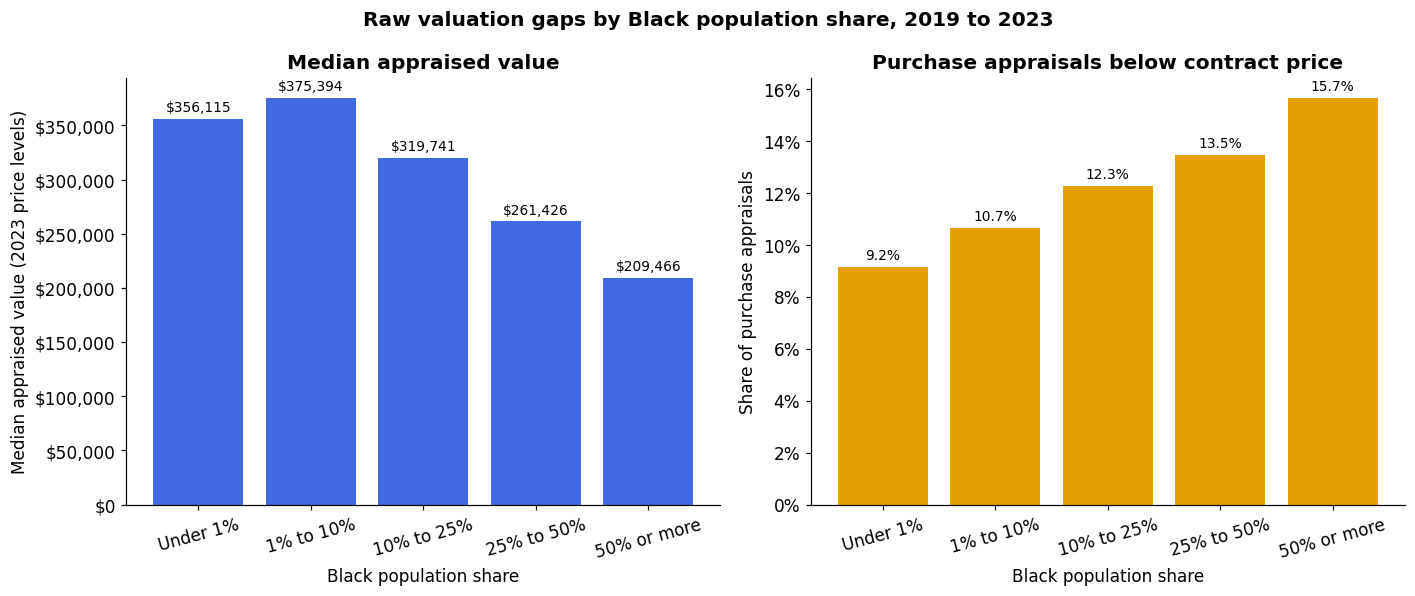

📊 Raw gaps by group (no controls):


,Tracts with value data,Median appraised value,Purchase appraisals,Appraisals below contract,Below-contract rate,Value vs. Under 1% group
Black population share,,,,,,
Under 1%,"22,034","$356,115","3,252,626","297,930",9.2%,+0.0%
1% to 10%,"30,427","$375,394","5,547,240","591,334",10.7%,+5.4%
10% to 25%,"11,951","$319,741","2,154,047","263,966",12.3%,-10.2%
25% to 50%,"6,266","$261,426","854,045","115,040",13.5%,-26.6%
50% or more,"4,750","$209,466","404,876","63,367",15.7%,-41.2%


💾 Figure saved: Figures/fig1_raw_gaps.png


In [6]:
summary_input = model_df.assign(
    n_below=model_df['share_below_contract'] * model_df['n_purchase']
)
group_summary = (
    summary_input
    .groupby('black_share_group', observed=True)
    .agg(
        tracts_with_value=('median_value_2023', 'count'),
        median_value=('median_value_2023', 'median'),
        purchase_appraisals=('n_purchase', 'sum'),
        appraisals_below=('n_below', 'sum'),
    )
)
group_summary['below_contract_rate'] = (
    group_summary['appraisals_below'] / group_summary['purchase_appraisals']
)
baseline_value = group_summary.loc['Under 1%', 'median_value']
group_summary['value_vs_under_1pct'] = group_summary['median_value'] / \
    baseline_value - 1

fig, (ax_value, ax_below) = plt.subplots(1, 2, figsize=(13, 5.5))
groups = group_summary.index.astype(str)

value_bars = ax_value.bar(
    groups,
    group_summary['median_value'],
    color=ROYAL_BLUE)
ax_value.bar_label(
    value_bars,
    labels=[f'${v:,.0f}' for v in group_summary['median_value']],
    padding=3,
    fontsize=9,
)
ax_value.yaxis.set_major_formatter(DOLLAR_FMT)
ax_value.set_title('Median appraised value')
ax_value.set_xlabel(DISPLAY_LABELS['black_share_group'])
ax_value.set_ylabel(DISPLAY_LABELS['median_value_2023'])

below_bars = ax_below.bar(
    groups,
    group_summary['below_contract_rate'],
    color=AMBER)
ax_below.bar_label(
    below_bars,
    labels=[f'{v:.1%}' for v in group_summary['below_contract_rate']],
    padding=3,
    fontsize=9,
)
ax_below.yaxis.set_major_formatter(PCT_FMT)
ax_below.set_title('Purchase appraisals below contract price')
ax_below.set_xlabel(DISPLAY_LABELS['black_share_group'])
ax_below.set_ylabel('Share of purchase appraisals')

for ax in (ax_value, ax_below):
    ax.tick_params(axis='x', rotation=15)

fig.suptitle(
    'Raw valuation gaps by Black population share, 2019 to 2023',
    fontweight='bold')
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'fig1_raw_gaps.png', dpi=300, bbox_inches='tight')
plt.show()

print('📊 Raw gaps by group (no controls):')
summary_labels = {
    'tracts_with_value': 'Tracts with value data',
    'median_value': 'Median appraised value',
    'purchase_appraisals': 'Purchase appraisals',
    'appraisals_below': 'Appraisals below contract',
    'below_contract_rate': 'Below-contract rate',
    'value_vs_under_1pct': 'Value vs. Under 1% group',
}
summary_formats = {
    'tracts_with_value': '{:,}',
    'median_value': '${:,.0f}',
    'purchase_appraisals': '{:,.0f}',
    'appraisals_below': '{:,.0f}',
    'below_contract_rate': '{:.1%}',
    'value_vs_under_1pct': '{:+.1%}',
}
display(
    group_summary.rename(columns=summary_labels)
    .rename_axis(DISPLAY_LABELS['black_share_group'])
    .style.format({summary_labels[c]: f for c, f in summary_formats.items()})
)
print(f'💾 Figure saved: {FIGURE_DIR.name}/fig1_raw_gaps.png')

**Interpretation:** Before any controls, both measures show a consistent pattern. Median appraised value peaks in tracts that are 1% to 10% Black (`$375,394`), then falls with each step up in Black population share, reaching `$209,466` in majority-Black tracts, 41.2% below the Under 1% group (`$356,115`). The below-contract rate rises across every group, from 9.2% of purchase appraisals in tracts under 1% Black to 15.7% in majority-Black tracts. A buyer in a majority-Black tract was about 1.7 times as likely to receive an appraisal below the agreed price.

Two features of the chart guide the next steps. First, the Under 1% group is not the highest-value group. One likely reason is that tracts with almost no Black residents include many rural and small-town areas where homes cost less, so this comparison group mixes very different housing markets. Later models therefore compare tracts within the same local housing market rather than nationally. Second, the 41.2% raw value gap is larger than the 23% gap Perry et al. (2018) reported after controls, which is expected: part of a raw gap reflects differences in housing age, size, and neighborhood income that Section 3 accounts for.

The below-contract rate is the more direct of the two signals, because the contract price already reflects what a buyer agreed to pay. Even so, below-contract appraisals may be more common in lower-priced markets regardless of racial composition, so the RQ2 models also account for price level before attributing any remaining gap to it.

### **Step 2.3: Compare housing and neighborhood characteristics across groups**

The raw gaps in Step 2.2 could reflect real differences in the housing itself. If homes in majority-Black tracts tend to be older or smaller, part of the value gap would be expected regardless of who lives there. This step compares the characteristics the models will control for across the five groups, using only tracts with usable appraisal data so the comparison matches the modeling sample.

The characteristics fall into the two groups described in Step 1.2. Housing structure (year built, rooms, and single-family detached share) describes the homes being appraised, and controlling for it is uncontroversial. Neighborhood conditions (income, education, homeownership, vacancy, and unemployment) are different: they are partly outcomes of the same discrimination this project studies, so controlling for them can absorb part of a real gap. Showing how strongly each one tracks Black population share makes that tradeoff visible before the models depend on it.

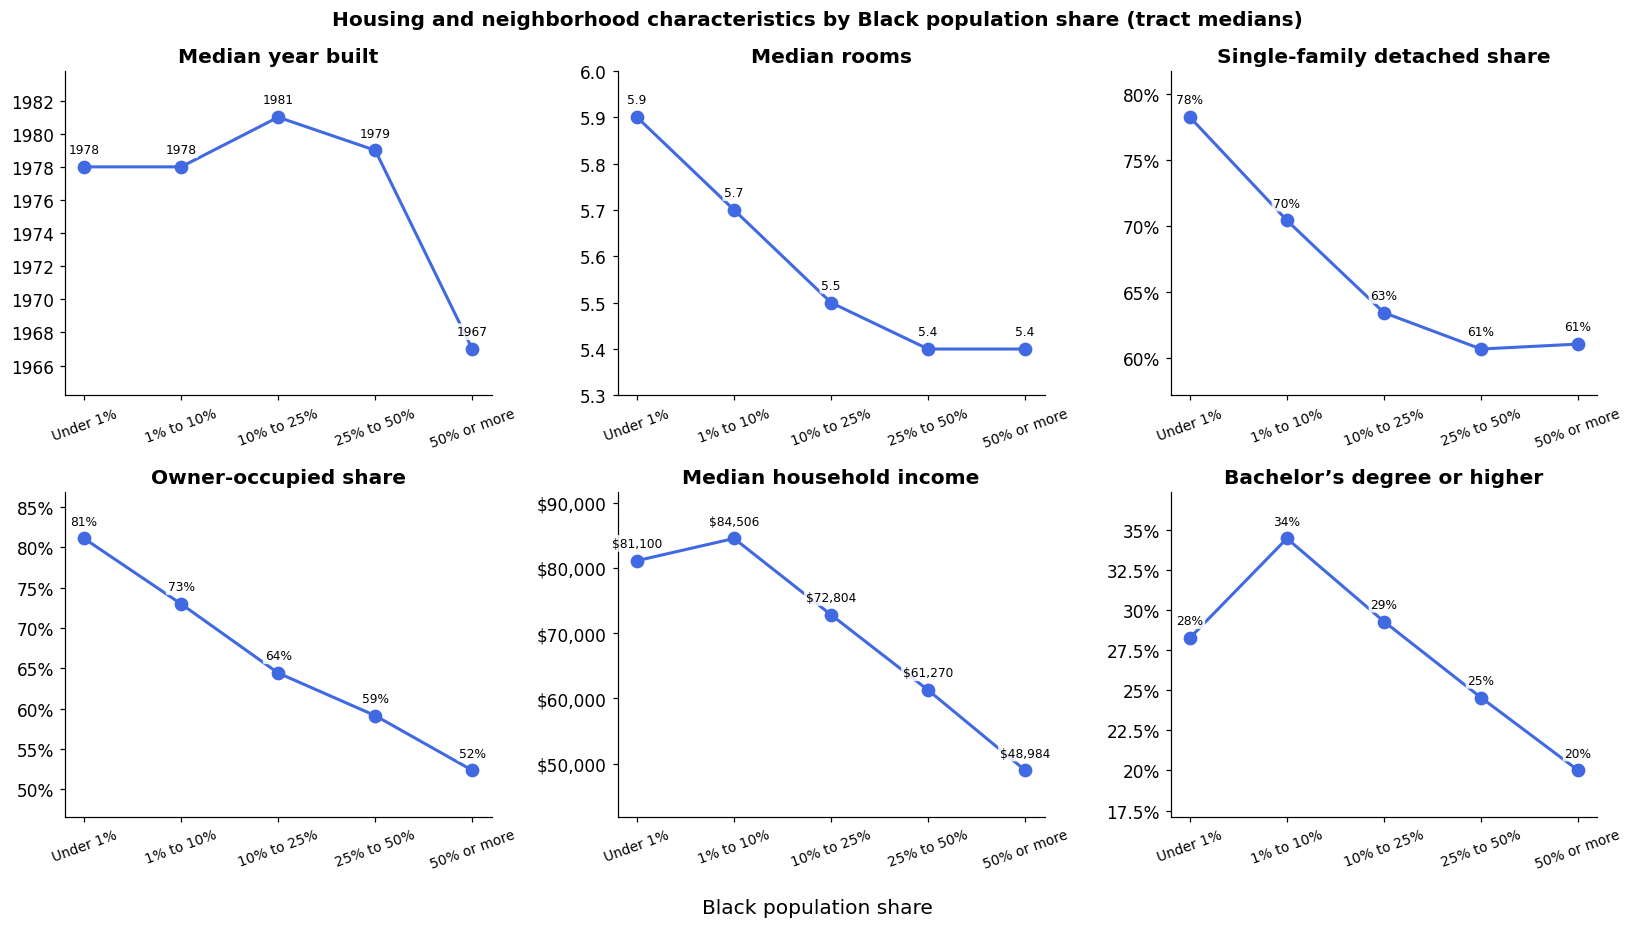

🏗️  Tract medians by group (75,428 tracts with appraisal data):


,Median year built,Median rooms,Single-family detached share,Owner-occupied share,Vacancy rate,Median household income,Bachelor’s degree or higher,Unemployment rate
Black population share,,,,,,,,
Under 1%,1978,5.9,78.2%,81.1%,7.9%,"$81,100",28.3%,3.7%
1% to 10%,1978,5.7,70.4%,73.0%,6.2%,"$84,506",34.5%,4.0%
10% to 25%,1981,5.5,63.4%,64.4%,6.8%,"$72,804",29.3%,4.6%
25% to 50%,1979,5.4,60.7%,59.1%,8.7%,"$61,270",24.5%,5.6%
50% or more,1967,5.4,61.1%,52.3%,11.2%,"$48,984",20.0%,8.1%



🔗 Correlation with Black population share (tract level):
   Owner-occupied share             -0.31
   Median household income          -0.28
   Bachelor’s degree or higher      -0.20
   Single-family detached share     -0.19
   Median rooms                     -0.14
   Median year built                -0.11
   Vacancy rate                     +0.05
   Unemployment rate                +0.32

💾 Figure saved: Figures/fig2_controls_by_group.png


In [7]:
control_cols = [
    'median_year_built',
    'median_rooms',
    'sf_detached_share',
    'owner_share',
    'vacancy_rate',
    'median_hh_income',
    'bachelors_plus_share',
    'unemployment_rate',
]
value_sample = model_df[model_df['has_value_data']]

control_profile = (
    value_sample
    .groupby('black_share_group', observed=True)[control_cols]
    .median()
)

panels = [
    ('median_year_built', lambda v: f'{v:.0f}', None),
    ('median_rooms', lambda v: f'{v:.1f}', None),
    ('sf_detached_share', lambda v: f'{v:.0%}', PCT_FMT),
    ('owner_share', lambda v: f'{v:.0%}', PCT_FMT),
    ('median_hh_income', lambda v: f'${v:,.0f}', DOLLAR_FMT),
    ('bachelors_plus_share', lambda v: f'{v:.0%}', PCT_FMT),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
groups = control_profile.index.astype(str)

for ax, (col, label_fmt, axis_fmt) in zip(axes.flat, panels):
    values = control_profile[col]
    ax.plot(
        groups,
        values,
        marker='o',
        markersize=8,
        linewidth=2,
        color=ROYAL_BLUE)
    for x, y in zip(groups, values):
        ax.annotate(
            label_fmt(y), (x, y), textcoords='offset points', xytext=(
                0, 9), ha='center', fontsize=8, bbox=dict(
                boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.85))
    if axis_fmt is not None:
        ax.yaxis.set_major_formatter(axis_fmt)
    ax.set_title(DISPLAY_LABELS[col])
    ax.tick_params(axis='x', rotation=20, labelsize=9)
    ax.margins(y=0.2)

axes[0, 0].yaxis.set_major_locator(MaxNLocator(integer=True))

fig.suptitle(
    'Housing and neighborhood characteristics by Black population share (tract medians)',
    fontweight='bold')
fig.supxlabel(DISPLAY_LABELS['black_share_group'])
fig.tight_layout()
fig.savefig(
    FIGURE_DIR /
    'fig2_controls_by_group.png',
    dpi=300,
    bbox_inches='tight')
plt.show()

table_formats = {
    'median_year_built': '{:.0f}',
    'median_rooms': '{:.1f}',
    'sf_detached_share': '{:.1%}',
    'owner_share': '{:.1%}',
    'vacancy_rate': '{:.1%}',
    'median_hh_income': '${:,.0f}',
    'bachelors_plus_share': '{:.1%}',
    'unemployment_rate': '{:.1%}',
}
print(
    f'🏗️  Tract medians by group ({len(value_sample):,} tracts with appraisal data):')
display(
    control_profile.rename(columns=DISPLAY_LABELS)
    .rename_axis(DISPLAY_LABELS['black_share_group'])
    .style.format({DISPLAY_LABELS[c]: f for c, f in table_formats.items()})
)

correlations = (
    value_sample[control_cols]
    .corrwith(value_sample['black_share'])
    .sort_values()
)
print('\n🔗 Correlation with Black population share (tract level):')
for col, r in correlations.items():
    print(f'   {DISPLAY_LABELS[col]:<32} {r:+.2f}')
print(f'\n💾 Figure saved: {FIGURE_DIR.name}/fig2_controls_by_group.png')

**Interpretation:** Majority-Black tracts differ from tracts under 1% Black on every characteristic, but the differences are larger for neighborhood conditions than for the homes themselves.

On housing structure, homes in majority-Black tracts are older (median year built 1967 versus 1978), slightly smaller (5.4 rooms versus 5.9), and less often single-family detached (61% versus 78%). These differences describe the housing being appraised, so the models control for them, and part of the raw gap in Step 2.2 is expected to shrink as a result.

Neighborhood conditions show wider gaps. Median household income is `$48,984` in majority-Black tracts compared with `$81,100` in tracts under 1% Black, about 40% lower, and homeownership is 52% compared with 81%. These measures also track Black population share more closely than any housing characteristic: the strongest correlations are with unemployment (+0.32), homeownership (-0.31), and income (-0.28), compared with -0.11 to -0.19 for the housing measures. The 1% to 10% group has the highest income and education of any group, which matches its peak in appraised value in Step 2.2.

This shapes how the models should be read. The income gap is nearly as large as the 41.2% raw value gap, so a model that controls for income could account for most of it. That result would not necessarily mean race plays no role, because income, homeownership, and education in these neighborhoods can themselves reflect the history this project examines, including redlining and the wealth residents could not build when their homes were valued lower. Section 3 therefore reports the gap after housing controls alone and again after adding neighborhood controls, and treats the two results as a range of plausible estimates rather than choosing one.

## **3. Modeling**

### **Step 3.1: Estimate the market gap (RQ1)**

This step estimates how much lower appraised values are in each Black population share group than in tracts under 1% Black, and how much of that gap remains as controls are added. Four models are fit in sequence:

1. **Raw (national):** group differences only, comparing tracts across the whole country.
2. **Within county:** each tract is compared only with other tracts in the same county, which removes differences in regional price levels.
3. **Plus housing controls:** adds median rooms, median year built, and single-family detached share, which describe the homes being appraised.
4. **Plus neighborhood controls:** adds income, education, homeownership, vacancy, and unemployment. As Step 2.3 showed, these are partly shaped by discrimination themselves, so Models 3 and 4 together bound the plausible gap rather than one being treated as the answer.

**Why county rather than metro area.** The proposal named metro areas, following Perry et al. (2018). Counties are used here instead because every tract has a county code, while FHFA identifies only the 100 largest metros, and because counties are smaller and closer to a true local housing market. A metro-area version is fit in Section 4 as a robustness check.

**Reading the results.** The models predict the logarithm of appraised value, so each group coefficient converts to a percentage gap, the same form as the 23% reported by Perry et al. (2018). Tracts are weighted by their number of appraisals, so estimates backed by more appraisals count more. Standard errors are clustered by county, because tracts in the same county share market conditions and are not fully independent observations. Counties are handled by subtracting each county's average from every variable rather than adding over 3,000 county indicators, which produces identical estimates with far less memory. Counties with only one tract are dropped, since they contain no within-county comparison.

In [8]:
def demean_within(df, cols, weights, groups):
    '''Subtract each group's weighted mean so only within-county differences remain.'''
    weighted_sum = df[cols].mul(
        weights, axis=0).groupby(groups).transform('sum')
    weight_total = weights.groupby(groups).transform('sum')
    return df[cols] - weighted_sum.div(weight_total, axis=0)


def fit_tract_model(
        df,
        outcome,
        regressors,
        weight_col,
        county_fe=True,
        group_col='county_fips'):
    '''Weighted least squares with clustered errors, optionally within a market group.'''
    cols = [outcome] + regressors
    weights = df[weight_col]
    if county_fe:
        data = demean_within(df, cols, weights, df[group_col])
        formula = f'{outcome} ~ ' + ' + '.join(regressors) + ' - 1'
    else:
        data = df[cols]
        formula = f'{outcome} ~ ' + ' + '.join(regressors)
    clusters = pd.factorize(df[group_col])[0]
    return smf.wls(formula, data=data, weights=weights).fit(
        cov_type='cluster', cov_kwds={'groups': clusters}
    )


def gap_table(models, terms, transform=lambda b: np.exp(b) - 1):
    '''Convert coefficients into gaps with 95% intervals.'''
    rows = []
    for name, result in models.items():
        ci = result.conf_int()
        for level, term in terms.items():
            if term not in result.params:
                continue
            rows.append({
                'model': name,
                'group': level,
                'gap': transform(result.params[term]),
                'ci_low': transform(ci.loc[term, 0]),
                'ci_high': transform(ci.loc[term, 1]),
                'p_value': result.pvalues[term],
            })
    return pd.DataFrame(rows)


rq1_cols = (
    ['log_value', 'n_all', 'county_fips', 'black_share_group']
    + HOUSING_CONTROLS + NEIGHBORHOOD_CONTROLS
)
rq1_df = (
    model_df.loc[model_df['has_value_data']]
    .assign(log_income=lambda d: np.log(d['median_hh_income']))
    [rq1_cols]
    .dropna()
)
for level, dummy in GROUP_DUMMIES.items():
    rq1_df[dummy] = (rq1_df['black_share_group'] == level).astype(float)

county_sizes = rq1_df['county_fips'].map(rq1_df['county_fips'].value_counts())
n_singletons = (county_sizes < 2).sum()
rq1_df = rq1_df[county_sizes >= 2].reset_index(drop=True)

group_terms = list(GROUP_DUMMIES.values())
model_specs = {
    'Raw (national)': (group_terms, False),
    'Within county': (group_terms, True),
    '+ Housing': (group_terms + HOUSING_CONTROLS, True),
    '+ Neighborhood': (group_terms + HOUSING_CONTROLS + NEIGHBORHOOD_CONTROLS, True),
}
rq1_models = {
    name: fit_tract_model(rq1_df, 'log_value', regressors, 'n_all', fe)
    for name, (regressors, fe) in model_specs.items()
}
rq1_gaps = gap_table(rq1_models, GROUP_DUMMIES)

print(
    f'🧮 RQ1 sample: {len(rq1_df):,} tracts in {rq1_df["county_fips"].nunique():,} counties '
    f'({n_singletons:,} single-tract counties dropped)')
for name, result in rq1_models.items():
    r2_label = 'R²' if name == 'Raw (national)' else 'within-county R²'
    print(f'   {name:<16} {r2_label}: {result.rsquared:.3f}')

rq1_gaps['display'] = rq1_gaps.apply(
    lambda r: f'{r.gap:+.1%} ({r.ci_low:+.1%} to {r.ci_high:+.1%})', axis=1
)
gap_display = (
    rq1_gaps.pivot(index='group', columns='model', values='display')
    .reindex(index=list(GROUP_DUMMIES), columns=list(model_specs))
    .rename_axis(index=DISPLAY_LABELS['black_share_group'], columns=None)
)
print('\n📉 Appraised value gap vs. tracts under 1% Black (95% confidence interval):')
display(gap_display)

🧮 RQ1 sample: 74,802 tracts in 2,786 counties (222 single-tract counties dropped)
   Raw (national)   R²: 0.068
   Within county    within-county R²: 0.164
   + Housing        within-county R²: 0.394
   + Neighborhood   within-county R²: 0.684

📉 Appraised value gap vs. tracts under 1% Black (95% confidence interval):


,Raw (national),Within county,+ Housing,+ Neighborhood
Black population share,,,,
1% to 10%,-5.1% (-8.3% to -1.8%),-12.1% (-13.5% to -10.7%),-10.1% (-11.3% to -8.8%),-6.4% (-7.1% to -5.7%)
10% to 25%,-22.2% (-26.9% to -17.2%),-28.5% (-30.3% to -26.7%),-22.9% (-24.7% to -21.0%),-12.1% (-13.1% to -11.0%)
25% to 50%,-33.7% (-38.3% to -28.8%),-39.5% (-41.1% to -37.7%),-31.5% (-33.3% to -29.6%),-14.8% (-16.2% to -13.4%)
50% or more,-44.2% (-50.1% to -37.6%),-52.4% (-55.0% to -49.7%),-44.6% (-47.3% to -41.8%),-20.7% (-23.7% to -17.5%)


**Interpretation:** Appraised values are lower in tracts with higher Black population shares in every model, and the gap grows with each step up in Black share. For majority-Black tracts, the gap is 44.2% before any controls, 52.4% when tracts are compared only within their own county, 44.6% after adding housing controls, and 20.7% after adding neighborhood controls. Every 95% confidence interval excludes zero, so RQ1's hypothesis is supported: a gap remains after controls.

The gap widens rather than narrows when the comparison moves within counties. This suggests majority-Black tracts are concentrated in counties with higher overall home prices, such as large urban counties, so a national comparison partly sets them against lower-priced rural tracts. Within the same county, the contrast is sharper. The same shift explains why the 1% to 10% group, which showed a premium in Step 2.2, shows a 12.1% gap once compared within its county.

Housing controls explain about 8 percentage points of the within-county gap for majority-Black tracts, and neighborhood controls explain about 24 more. Because neighborhood conditions are themselves shaped by the history this project examines (Step 2.3), the two estimates bound the plausible gap rather than one replacing the other: homes in majority-Black tracts are appraised roughly 21% to 45% below comparable homes in the same county. The fully controlled estimate of 20.7% is close to the 23% reported by Perry et al. (2018), despite a different data source, appraisals rather than self-reported values, and a different definition of the local market.

Explanatory power rises from a within-county R² of 0.164 to 0.684 across the models, so the full model accounts for most of the variation in value within counties. The remaining gap is a tract-level association rather than proof of bias in individual appraisals, and it may partly reflect neighborhood features not measured here, such as school quality or proximity to jobs. It also measures what the market as a whole pays. Step 3.3 tests the appraisal step itself by comparing appraisals with contract prices.

### **Step 3.2: Visualize how the gap changes as controls are added**

This figure shows the Step 3.1 results for all four Black population share groups across all four models. Each marker is the estimated gap relative to tracts under 1% Black, and each vertical bar is its 95% confidence interval; bars that stay below zero indicate a gap that is statistically distinguishable from no gap. Models are distinguished by both color and marker shape so the figure remains readable without color.

The dashed line marks the 23% gap reported by Perry et al. (2018) for majority-Black neighborhoods, so the fully controlled estimate can be compared against the earlier study directly.

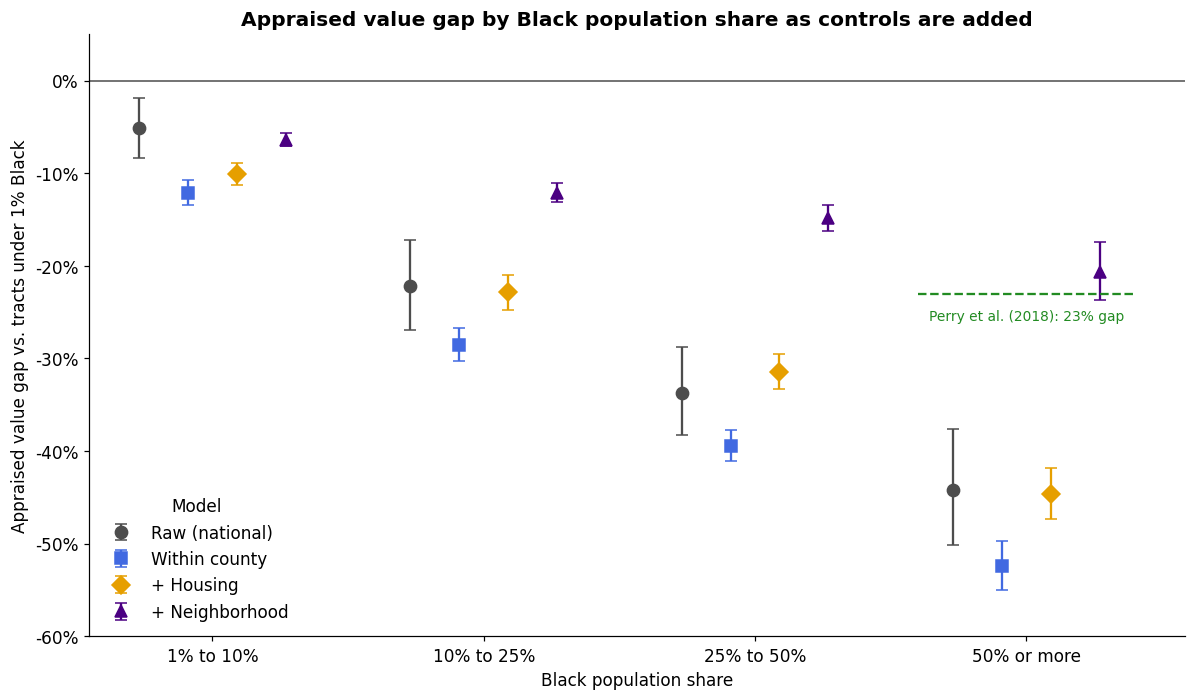

🎯 Majority-Black range: -20.7% (all controls) to -44.6% (housing controls only)
💾 Figure saved: Figures/fig3_rq1_gaps.png


In [9]:
model_styles = {
    'Raw (national)': (DARK_GRAY, 'o'),
    'Within county': (ROYAL_BLUE, 's'),
    '+ Housing': (AMBER, 'D'),
    '+ Neighborhood': (PURPLE, '^'),
}
group_labels = list(GROUP_DUMMIES)
x_base = np.arange(len(group_labels))
offsets = np.linspace(-0.27, 0.27, len(model_styles))

fig, ax = plt.subplots(figsize=(11, 6.5))

for offset, (name, (color, marker)) in zip(offsets, model_styles.items()):
    subset = rq1_gaps[rq1_gaps['model'] == name].set_index(
        'group').loc[group_labels]
    lower = subset['gap'] - subset['ci_low']
    upper = subset['ci_high'] - subset['gap']
    ax.errorbar(
        x_base + offset,
        subset['gap'],
        yerr=[
            lower,
            upper],
        fmt=marker,
        color=color,
        markersize=8,
        capsize=4,
        linewidth=1.5,
        label=name,
    )

majority_x = group_labels.index('50% or more')
ax.hlines(-0.23, majority_x - 0.4, majority_x + 0.4,
          colors=FOREST_GREEN, linestyles='--', linewidth=1.5)
ax.annotate('Perry et al. (2018): 23% gap', (majority_x, -0.23),
            xytext=(0, -10), textcoords='offset points',
            ha='center', va='top', fontsize=9, color=FOREST_GREEN)

ax.axhline(0, color=DARK_GRAY, linewidth=1)
ax.set_xticks(x_base, group_labels)
ax.set_ylim(-0.6, 0.05)
ax.yaxis.set_major_formatter(PCT_FMT)
ax.set_xlabel(DISPLAY_LABELS['black_share_group'])
ax.set_ylabel('Appraised value gap vs. tracts under 1% Black')
ax.set_title(
    'Appraised value gap by Black population share as controls are added')
ax.legend(title='Model', frameon=False, loc='lower left')

fig.tight_layout()
fig.savefig(FIGURE_DIR / 'fig3_rq1_gaps.png', dpi=300, bbox_inches='tight')
plt.show()

majority = rq1_gaps[rq1_gaps['group'] == '50% or more'].set_index('model')[
    'gap']
print(
    f'🎯 Majority-Black range: {majority["+ Neighborhood"]:.1%} (all controls) to '
    f'{majority["+ Housing"]:.1%} (housing controls only)')
print(f'💾 Figure saved: {FIGURE_DIR.name}/fig3_rq1_gaps.png')

**Interpretation:** The figure shows two patterns at once. Reading left to right, the gap deepens with every step up in Black population share in all four models. Reading within each group, the same ordering repeats: the within-county comparison produces the largest gap, housing controls narrow it modestly, and neighborhood controls narrow it most.

The confidence intervals also change across models. The raw national estimates have the widest intervals because they mix housing markets with very different price levels; comparing tracts within the same county removes that noise and tightens the estimates considerably. Even in the fully controlled model, no interval comes close to zero.

For majority-Black tracts, the fully controlled estimate of 20.7% has a 95% confidence interval of 17.5% to 23.7%, which contains the 23% reported by Perry et al. (2018). The two studies are therefore statistically consistent, even though this analysis uses lender appraisals rather than self-reported values and compares tracts within counties rather than metro areas. That agreement suggests the gap is not an artifact of how homeowners estimate their own home values, which was a central limitation of the earlier study.

### **Step 3.3: Estimate the appraisal gap (RQ2)**

RQ1 measured how the market values homes in majority-Black tracts. This step isolates the appraisal itself. When a buyer and seller agree on a price, the appraisal is supposed to confirm whether the home supports it. The outcome here is the share of purchase appraisals that came in below that agreed price, so the market's own valuation serves as the benchmark.

The models follow the same within-county structure as RQ1, with one change in the controls. Step 2.2 noted that below-contract appraisals may be more common in lower-priced markets regardless of racial composition, so the third model adds the tract's appraised value level alongside the housing controls. That control carries the same caution as the neighborhood measures: Step 3.1 showed that value levels are themselves lower in majority-Black tracts, so the fully controlled estimate is again a lower bound rather than the single answer.

**Why a linear model.** The proposal named a fractional logit, which is designed for outcomes that are shares. With nearly 3,000 counties, however, nonlinear models with county controls produce biased estimates when many counties have few tracts. A linear model keeps the same within-county comparison used for RQ1 and reports gaps directly in percentage points. A fractional logit with state-level controls is fit in Section 4 to confirm the results do not depend on this choice.

Tracts are weighted by their number of purchase appraisals, and the sample is limited to tracts with purchase data, which Step 1.3 showed covers only half of majority-Black tracts. Results describe majority-Black tracts with active Enterprise-backed purchase markets.

In [10]:
rq2_cols = (['share_below_contract',
             'log_value',
             'n_purchase',
             'county_fips',
             'black_share_group'] + HOUSING_CONTROLS + NEIGHBORHOOD_CONTROLS)
rq2_df = (
    model_df.loc[model_df['has_purchase_data']]
    .assign(log_income=lambda d: np.log(d['median_hh_income']))
    [rq2_cols]
    .dropna()
)
for level, dummy in GROUP_DUMMIES.items():
    rq2_df[dummy] = (rq2_df['black_share_group'] == level).astype(float)

rq2_county_sizes = rq2_df['county_fips'].map(
    rq2_df['county_fips'].value_counts())
rq2_singletons = (rq2_county_sizes < 2).sum()
rq2_df = rq2_df[rq2_county_sizes >= 2].reset_index(drop=True)

price_and_housing = ['log_value'] + HOUSING_CONTROLS
rq2_specs = {
    'Raw (national)': (group_terms, False),
    'Within county': (group_terms, True),
    '+ Price & housing': (group_terms + price_and_housing, True),
    '+ Neighborhood': (group_terms + price_and_housing + NEIGHBORHOOD_CONTROLS, True),
}
rq2_models = {
    name: fit_tract_model(rq2_df, 'share_below_contract', regressors, 'n_purchase', fe)
    for name, (regressors, fe) in rq2_specs.items()
}
rq2_gaps = gap_table(rq2_models, GROUP_DUMMIES, transform=lambda b: b)

reference = rq2_df[rq2_df['black_share_group'] == 'Under 1%']
baseline_rate = np.average(
    reference['share_below_contract'],
    weights=reference['n_purchase'])

print(
    f'🧾 RQ2 sample: {len(rq2_df):,} tracts in {rq2_df["county_fips"].nunique():,} counties '
    f'({rq2_singletons:,} single-tract counties dropped)')
print(
    f'📏 Baseline: {baseline_rate:.1%} of purchase appraisals below contract in tracts under 1% Black')
for name, result in rq2_models.items():
    r2_label = 'R²' if name == 'Raw (national)' else 'within-county R²'
    print(f'   {name:<18} {r2_label}: {result.rsquared:.3f}')

rq2_gaps['display'] = rq2_gaps.apply(
    lambda r: f'{r.gap * 100:+.1f} pts ({r.ci_low * 100:+.1f} to {r.ci_high * 100:+.1f})',
    axis=1)
rq2_display = (
    rq2_gaps.pivot(index='group', columns='model', values='display')
    .reindex(index=list(GROUP_DUMMIES), columns=list(rq2_specs))
    .rename_axis(index=DISPLAY_LABELS['black_share_group'], columns=None)
)
print('\n📈 Below-contract rate gap vs. tracts under 1% Black, in percentage points (95% CI):')
display(rq2_display)

price_coef = rq2_models['+ Price & housing'].params['log_value']
print(f'\n💲 Price level effect: 10% higher appraised values go with a '
      f'{price_coef * np.log(1.1) * 100:+.2f} point change in the below-contract rate')

full_gap = rq2_gaps.query(
    "model == '+ Neighborhood' and group == '50% or more'")['gap'].iloc[0]
print(
    f'⚖️  Majority-Black tracts, all controls: {(baseline_rate + full_gap) / baseline_rate:.2f}x '
    f'the baseline rate of below-contract appraisals')

🧾 RQ2 sample: 65,049 tracts in 2,439 counties (261 single-tract counties dropped)
📏 Baseline: 9.2% of purchase appraisals below contract in tracts under 1% Black
   Raw (national)     R²: 0.064
   Within county      within-county R²: 0.042
   + Price & housing  within-county R²: 0.154
   + Neighborhood     within-county R²: 0.157

📈 Below-contract rate gap vs. tracts under 1% Black, in percentage points (95% CI):


,Raw (national),Within county,+ Price & housing,+ Neighborhood
Black population share,,,,
1% to 10%,+1.5 pts (+1.1 to +1.8),+0.6 pts (+0.4 to +0.7),-0.2 pts (-0.3 to -0.0),-0.2 pts (-0.3 to -0.0)
10% to 25%,+3.1 pts (+2.5 to +3.6),+1.7 pts (+1.4 to +2.0),-0.1 pts (-0.4 to +0.2),-0.2 pts (-0.4 to +0.1)
25% to 50%,+4.3 pts (+3.4 to +5.3),+3.0 pts (+2.6 to +3.4),+0.5 pts (+0.1 to +0.8),+0.3 pts (-0.1 to +0.7)
50% or more,+6.5 pts (+5.0 to +7.9),+5.3 pts (+4.4 to +6.1),+1.7 pts (+1.0 to +2.4),+1.4 pts (+0.7 to +2.2)



💲 Price level effect: 10% higher appraised values go with a -0.52 point change in the below-contract rate
⚖️  Majority-Black tracts, all controls: 1.16x the baseline rate of below-contract appraisals


**Interpretation:** Before controls, purchase appraisals in majority-Black tracts came in below the contract price 6.5 percentage points more often than in tracts under 1% Black, and the gap remains 5.3 points when tracts are compared within the same county. Most of that within-county gap, however, tracks price level rather than racial composition directly. Lower-valued tracts see more below-contract appraisals in general: each 10% decrease in appraised value goes with a rate about half a point higher. Because Step 3.1 found values in majority-Black tracts roughly 45% to 52% lower within the same county, price level alone accounts for most of the difference.

After controlling for price, housing, and neighborhood conditions, a smaller gap remains for majority-Black tracts only: 1.4 percentage points (95% confidence interval 0.7 to 2.2), meaning purchase appraisals there fall below the contract price about 1.16 times as often as in tracts under 1% Black. For tracts that are 10% to 50% Black, the fully controlled intervals include zero. RQ2's hypothesis is therefore partially supported: a statistically clear appraisal gap exists in majority-Black tracts, but it is much smaller than the market gap measured in RQ1.

The price control requires the same caution as the neighborhood controls. Price levels in majority-Black tracts are themselves lower, as RQ1 showed, so controlling for price removes part of the gap that the earlier devaluation created. One reading consistent with these results is that the appraisal gap largely follows from the market gap: when homes in a neighborhood have long been valued lower, appraisals there are more likely to fall short of what a buyer offers. The range of plausible estimates runs from 1.4 points with all controls to 5.3 points within county.

Two limits apply. The models explain little of the variation in below-contract rates (within-county R² of 0.157), so most of what drives an individual tract's rate is not captured here. And as Step 1.3 showed, the sample covers only half of majority-Black tracts, those with enough Enterprise-backed purchases to be reported.

### **Step 3.4: Test the legacy of redlining (RQ3)**

In the 1930s, the Home Owners' Loan Corporation graded neighborhoods in about 150 cities from A ("best") to D ("hazardous"), and D-graded areas were outlined in red. The Historic Redlining Indicator converts those grades to 2020 census tracts on a scale from 1 to 4, where higher scores mean a tract was more heavily graded toward D. This step asks whether that score predicts today's appraisal outcomes beyond current racial composition.

The test works by comparing models. A model with only the redlining score shows its total association with today's values. Adding Black population share shows whether redlining still matters once current composition is known, and the reverse comparison shows how much of today's majority-Black gap travels through the redlining history. Housing and neighborhood controls are then added as in RQ1. Both outcomes are tested: appraised value (the market gap) and the below-contract rate (the appraisal gap).

Two cautions shape the reading. The sample covers only HOLC-graded cities, mostly older urban cores, so results describe those places rather than the nation. And HOLC grades both recorded the conditions of the 1930s, including racial composition, and shaped lending afterward, so the score captures that combined legacy rather than the effect of the map alone.

In [11]:
def prepare_sample(df, cols):
    '''Add log income and group dummies, drop incomplete rows and single-tract counties.'''
    sample = (
        df.assign(
            log_income=lambda d: np.log(
                d['median_hh_income']))[
            cols +
            [
                'county_fips',
                'black_share_group'] +
            HOUSING_CONTROLS +
            NEIGHBORHOOD_CONTROLS] .dropna())
    for level, dummy in GROUP_DUMMIES.items():
        sample[dummy] = (sample['black_share_group'] == level).astype(float)
    sizes = sample['county_fips'].map(sample['county_fips'].value_counts())
    return sample[sizes >= 2].reset_index(drop=True), int((sizes < 2).sum())


def redlining_specs(structure_controls, structure_label):
    '''Nested models separating redlining from current racial composition.'''
    return {
        'Redlining only': ['hri_score'],
        'Black share only': group_terms,
        'Redlining + Black share': ['hri_score'] + group_terms,
        structure_label: ['hri_score'] + group_terms + structure_controls,
        '+ Neighborhood': ['hri_score'] + group_terms + structure_controls + NEIGHBORHOOD_CONTROLS,
    }


rq3_terms = {
    'Redlining score (per grade)': 'hri_score',
    'Majority-Black gap': 'grp_50_plus'}
has_hri = model_df['hri_score'].notna()

rq3_value_df, rq3_value_singles = prepare_sample(
    model_df[model_df['has_value_data'] & has_hri], ['log_value', 'n_all', 'hri_score']
)
rq3_value_specs = redlining_specs(HOUSING_CONTROLS, '+ Housing')
rq3_value_models = {
    name: fit_tract_model(rq3_value_df, 'log_value', regs, 'n_all')
    for name, regs in rq3_value_specs.items()
}
rq3_value = gap_table(rq3_value_models, rq3_terms)

rq3_below_df, rq3_below_singles = prepare_sample(
    model_df[model_df['has_purchase_data'] & has_hri],
    ['share_below_contract', 'log_value', 'n_purchase', 'hri_score'],
)
rq3_below_specs = redlining_specs(
    ['log_value'] + HOUSING_CONTROLS,
    '+ Price & housing')
rq3_below_models = {
    name: fit_tract_model(rq3_below_df, 'share_below_contract', regs, 'n_purchase')
    for name, regs in rq3_below_specs.items()
}
rq3_below = gap_table(rq3_below_models, rq3_terms, transform=lambda b: b)


def rq3_display(gaps, specs, fmt):
    '''Pivot RQ3 results into a terms-by-models table of formatted strings.'''
    gaps = gaps.assign(display=gaps.apply(fmt, axis=1))
    return (
        gaps.pivot(index='group', columns='model', values='display')
        .reindex(index=list(rq3_terms), columns=list(specs))
        .rename_axis(index=None, columns=None)
        .fillna('')
    )


def pct_fmt(r): return f'{r.gap:+.1%} ({r.ci_low:+.1%} to {r.ci_high:+.1%})'


def pts_fmt(
    r): return f'{r.gap * 100:+.1f} pts ({r.ci_low * 100:+.1f} to {r.ci_high * 100:+.1f})'


print(
    f'🗺️  RQ3 value sample: {len(rq3_value_df):,} HOLC-graded tracts in '
    f'{rq3_value_df["county_fips"].nunique():,} counties ({rq3_value_singles:,} single-tract counties dropped)')
print('\n🏚️  Appraised value (percent difference, 95% CI):')
display(rq3_display(rq3_value, rq3_value_specs, pct_fmt))

print(
    f'\n🧾 RQ3 below-contract sample: {len(rq3_below_df):,} HOLC-graded tracts')
print('\n📈 Below-contract rate (percentage points, 95% CI):')
display(rq3_display(rq3_below, rq3_below_specs, pts_fmt))

full_hri = rq3_value_models['+ Neighborhood'].params['hri_score']
print(f'\n📐 Full-scale contrast, all controls: a fully D-graded tract (score 4) vs. a fully '
      f'A-graded tract (score 1) differs in value by {np.exp(3 * full_hri) - 1:+.1%}')

gap_alone = rq3_value.query(
    "model == 'Black share only' and group == 'Majority-Black gap'")['gap'].iloc[0]
gap_with = rq3_value.query(
    "model == 'Redlining + Black share' and group == 'Majority-Black gap'")['gap'].iloc[0]
print(
    f'🔄 Majority-Black value gap in HOLC cities: {gap_alone:.1%} alone, {gap_with:.1%} once redlining is added')

🗺️  RQ3 value sample: 10,003 HOLC-graded tracts in 202 counties (10 single-tract counties dropped)

🏚️  Appraised value (percent difference, 95% CI):


,Redlining only,Black share only,Redlining + Black share,+ Housing,+ Neighborhood
Redlining score (per grade),-23.1% (-27.1% to -18.9%),,-19.2% (-22.9% to -15.2%),-12.0% (-15.1% to -8.8%),-2.8% (-4.7% to -0.9%)
Majority-Black gap,,-55.4% (-59.1% to -51.3%),-49.9% (-53.7% to -45.7%),-46.5% (-51.0% to -41.6%),-19.1% (-22.8% to -15.1%)



🧾 RQ3 below-contract sample: 7,189 HOLC-graded tracts

📈 Below-contract rate (percentage points, 95% CI):


,Redlining only,Black share only,Redlining + Black share,+ Price & housing,+ Neighborhood
Redlining score (per grade),+0.9 pts (+0.3 to +1.5),,+0.7 pts (+0.1 to +1.2),-0.1 pts (-0.5 to +0.3),-0.1 pts (-0.5 to +0.2)
Majority-Black gap,,+4.2 pts (+3.3 to +5.2),+3.9 pts (+2.9 to +4.9),+1.2 pts (+0.0 to +2.4),+1.2 pts (+0.1 to +2.2)



📐 Full-scale contrast, all controls: a fully D-graded tract (score 4) vs. a fully A-graded tract (score 1) differs in value by -8.1%
🔄 Majority-Black value gap in HOLC cities: -55.4% alone, -49.9% once redlining is added


**Interpretation:** In the 10,003 HOLC-graded tracts with appraisal data, the 1930s redlining score predicts lower appraised values today, and that association persists after accounting for current racial composition. On its own, each one-grade step toward D goes with values 23.1% lower; with Black population share added, the association remains 19.2% per grade, so RQ3's hypothesis is supported for appraised value. The association narrows as controls are added, to 12.0% per grade with housing controls and 2.8% per grade with neighborhood controls, but its confidence interval excludes zero in every model. Across the full scale, a fully D-graded tract is appraised roughly 32% below a fully A-graded tract in the same county with housing controls, and about 8% below with all controls. As in RQ1, the neighborhood conditions that narrow this estimate are partly products of the redlining itself, so the two figures bound the plausible legacy rather than one replacing the other.

For the below-contract rate, redlining shows no independent association once price level is included. Its association of 0.9 percentage points per grade falls to -0.1 points with an interval centered on zero after price and housing controls. This matches the RQ2 finding: the historical disadvantage works through lower market values, and lower values in turn go with more below-contract appraisals, rather than through a separate effect on the appraisal step.

Redlining explains a modest share of today's racial gap. Within HOLC-graded cities, the majority-Black value gap is 55.4% before redlining is considered and 49.9% after, so the 1930s grades account for about 5.5 percentage points of a gap that is otherwise not explained by the historical maps. The fully controlled majority-Black gaps in this sample, 19.1% for value and 1.2 points for below-contract appraisals, closely match the national estimates of 20.7% and 1.4 points, so the main findings hold in a separate subsample of older urban areas. The below-contract estimate in this smaller sample sits near the edge of statistical significance (interval 0.1 to 2.2 points), consistent with the larger national estimate but less precise.

### **Step 3.5: Test a mechanism: reliance on same-tract comparable sales**

RQ2 and RQ3 both suggest that the appraisal gap follows the market gap. One way that could happen runs through comparable sales. An appraiser values a home largely from recent sales of similar nearby homes, adjusting for their differences. If appraisers in majority-Black tracts draw more of their comparables from inside the same tract, and those sales reflect the tract's historically lower prices, appraisals there would be anchored low even when a buyer has agreed to pay more.

The mechanism makes three testable predictions, stated here before the results:

1. **Reliance:** Appraisals in majority-Black tracts draw a larger share of comparables from the same tract than appraisals in comparable tracts in the same county.
2. **Consequence:** In majority-Black tracts, a larger share of same-tract comparables goes with a higher below-contract rate.
3. **Explanation:** Accounting for comparable selection narrows the majority-Black below-contract gap from RQ2.

If the first or second prediction fails, the data do not support this mechanism, and the RQ2 interpretation remains one possible reading rather than an explained result.

Two limits apply. FHFA reports comparable-sale measures for purchases and refinances combined, so they approximate the comparables used in purchase appraisals rather than measuring them directly. And same-tract reliance partly reflects how many sales a tract has, which is why the models control for housing, price level, and neighborhood conditions within each county.

In [12]:
full_controls = group_terms + ['log_value'] + \
    HOUSING_CONTROLS + NEIGHBORHOOD_CONTROLS


def coef_summary(result, term, scale=1.0):
    '''Return a coefficient and its 95% interval, multiplied by scale.'''
    ci = result.conf_int().loc[term]
    return result.params[term] * scale, ci[0] * scale, ci[1] * scale


def fmt_interval(est, low, high, unit, decimals=1):
    return f'{est:+.{decimals}f} {unit} ({low:+.{decimals}f} to {high:+.{decimals}f})'


# Prediction 1: do majority-Black tracts rely more on same-tract comparables?
reliance_df, _ = prepare_sample(
    model_df[model_df['has_value_data']],
    ['comps_same_tract', 'comps_distance', 'log_value', 'n_all'],
)
reliance_specs = {
    'Same-tract comps share (+ Housing)': ('comps_same_tract', group_terms + HOUSING_CONTROLS, 100, 'pts'),
    'Same-tract comps share (all controls)': ('comps_same_tract', full_controls, 100, 'pts'),
    'Distance to comps (all controls)': ('comps_distance', full_controls, 1, 'miles'),
}

reference = reliance_df[reliance_df['black_share_group'] == 'Under 1%']
majority = reliance_df[reliance_df['black_share_group'] == '50% or more']
raw_ref = np.average(reference['comps_same_tract'], weights=reference['n_all'])
raw_maj = np.average(majority['comps_same_tract'], weights=majority['n_all'])
print(
    f'🔍 Raw share of comparables from the same tract: {raw_ref:.1%} (under 1% Black) '
    f'vs. {raw_maj:.1%} (majority-Black)')

print('\n🏘️  Prediction 1, majority-Black difference within county (95% CI):')
reliance_results = {}
for label, (outcome, regs, scale, unit) in reliance_specs.items():
    result = fit_tract_model(reliance_df, outcome, regs, 'n_all')
    est, low, high = coef_summary(result, 'grp_50_plus', scale)
    reliance_results[label] = (est, low, high)
    print(f'   {label:<40} {fmt_interval(est, low, high, unit, 2)}')

# Predictions 2 and 3: do same-tract comparables raise below-contract rates?
mech_df, _ = prepare_sample(
    model_df[model_df['has_purchase_data']],
    ['share_below_contract', 'log_value', 'n_purchase', 'comps_same_tract'],
)
comps_mean = np.average(
    mech_df['comps_same_tract'],
    weights=mech_df['n_purchase'])
mech_df['comps_c'] = mech_df['comps_same_tract'] - comps_mean
mech_df['comps_x_majority'] = mech_df['comps_c'] * mech_df['grp_50_plus']

mech_specs = {
    'RQ2 full model': full_controls,
    '+ Same-tract comps': full_controls + ['comps_c'],
    '+ Comps x majority-Black': full_controls + ['comps_c', 'comps_x_majority'],
}
mech_models = {
    name: fit_tract_model(mech_df, 'share_below_contract', regs, 'n_purchase')
    for name, regs in mech_specs.items()
}

mech_rows = {
    'Majority-Black gap': {},
    'Comps effect, other tracts (per +10 pts)': {},
    'Comps effect, majority-Black tracts (per +10 pts)': {},
}
for name, result in mech_models.items():
    mech_rows['Majority-Black gap'][name] = fmt_interval(
        *coef_summary(result, 'grp_50_plus', 100), 'pts', 2)
    if 'comps_c' in result.params:
        mech_rows['Comps effect, other tracts (per +10 pts)'][name] = fmt_interval(
            *coef_summary(result, 'comps_c', 10), 'pts', 2)
    if 'comps_x_majority' in result.params:
        combined = result.t_test('comps_c + comps_x_majority = 0')
        est = float(combined.effect[0]) * 10
        low, high = (combined.conf_int()[0] * 10).tolist()
        mech_rows['Comps effect, majority-Black tracts (per +10 pts)'][name] = fmt_interval(
            est, low, high, 'pts', 2)
        majority_slope = (est, low, high)

print('\n📈 Predictions 2 and 3, below-contract rate within county (95% CI):')
display(pd.DataFrame(mech_rows).T.reindex(columns=list(mech_specs)).fillna(''))

p1 = reliance_results['Same-tract comps share (all controls)']
gap_before = mech_models['RQ2 full model'].params['grp_50_plus'] * 100
gap_after = mech_models['+ Same-tract comps'].params['grp_50_plus'] * 100

print('\n🧪 Prediction check:')
print(
    f'   {"✅" if p1[1] > 0 else "❌"} 1. Reliance: majority-Black tracts draw '
    f'{p1[0]:+.2f} pts more of their comparables from the same tract')
print(
    f'   {"✅" if majority_slope[1] > 0 else "❌"} 2. Consequence: +10 pts of same-tract comparables in '
    f'majority-Black tracts goes with {majority_slope[0]:+.2f} pts in the below-contract rate')
print(
    f'   📏 3. Explanation: the majority-Black gap moves from {gap_before:+.2f} to {gap_after:+.2f} pts '
    f'when comparables are included ({(gap_before - gap_after) / gap_before:.0%} of the gap)')

🔍 Raw share of comparables from the same tract: 59.0% (under 1% Black) vs. 59.8% (majority-Black)

🏘️  Prediction 1, majority-Black difference within county (95% CI):
   Same-tract comps share (+ Housing)       +0.17 pts (-1.00 to +1.33)
   Same-tract comps share (all controls)    +2.03 pts (+0.11 to +3.95)
   Distance to comps (all controls)         -0.30 miles (-0.39 to -0.20)

📈 Predictions 2 and 3, below-contract rate within county (95% CI):


,RQ2 full model,+ Same-tract comps,+ Comps x majority-Black
Majority-Black gap,+1.45 pts (+0.69 to +2.21),+1.45 pts (+0.69 to +2.20),+1.56 pts (+0.82 to +2.30)
"Comps effect, other tracts (per +10 pts)",,+0.01 pts (-0.06 to +0.07),-0.02 pts (-0.09 to +0.05)
"Comps effect, majority-Black tracts (per +10 pts)",,,+0.80 pts (+0.55 to +1.05)



🧪 Prediction check:
   ✅ 1. Reliance: majority-Black tracts draw +2.03 pts more of their comparables from the same tract
   ✅ 2. Consequence: +10 pts of same-tract comparables in majority-Black tracts goes with +0.80 pts in the below-contract rate
   📏 3. Explanation: the majority-Black gap moves from +1.45 to +1.45 pts when comparables are included (0% of the gap)


**Interpretation:** The results support the mechanism only in part, and in a different form than predicted.

The first prediction receives weak support. Before controls, appraisals in majority-Black tracts and tracts under 1% Black drew nearly the same share of comparables from the same tract (59.8% versus 59.0%). Within county, the difference is 0.17 percentage points with housing controls, an interval that includes zero, and 2.03 points with all controls, an interval that only narrowly excludes zero. Comparables in majority-Black tracts are about 0.3 miles closer, which may partly reflect denser urban markets. Majority-Black tracts therefore show at most a small difference in how much appraisers rely on same-tract sales.

The second prediction is strongly supported, and the effect is specific to majority-Black tracts. There, each 10-point increase in the share of same-tract comparables goes with a below-contract rate 0.80 percentage points higher (95% confidence interval 0.55 to 1.05). In all other tracts, the same increase has no measurable effect (-0.02 points, interval -0.09 to 0.05). Because the same-tract share varies by about 19 points across tracts, a typical difference in comparable selection within majority-Black tracts corresponds to roughly 1.5 points in the below-contract rate, about the size of the entire gap remaining in RQ2.

The third prediction is not supported: including comparable selection leaves the majority-Black gap unchanged at 1.45 points. Because appraisers in majority-Black tracts do not rely on same-tract sales much more than elsewhere, differences in comparable selection cannot explain the average gap.

Taken together, the evidence points to a different mechanism than the one proposed. The issue is not that appraisers choose more local comparables in majority-Black tracts, but that the same practice carries different consequences there. Relying on nearby sales is neutral in most neighborhoods, but in majority-Black tracts it goes with more appraisals falling short of the agreed price, consistent with local sales carrying the history of lower valuations measured in RQ1 and RQ3. This remains a tract-level association: it may also reflect features of markets where appraisers rely heavily on same-tract sales, such as thinner or more uniform housing stock, and appraisal-level data would be needed to confirm it.

## **4. Robustness Checks**

Each check in this section changes one analytic choice to see whether the main findings depend on it. A finding that holds across reasonable alternatives is stronger than one tied to a single specification, and any check that changes a result is reported as such.

### **Step 4.1: Define the housing market as the metro area**

Section 3 compared tracts within the same county. Perry et al. (2018) compared tracts within the same metro area, and the proposal planned to do the same. This step refits RQ1 and RQ2 within metropolitan areas, using the Office of Management and Budget's 2023 county-to-metro delineation.

Metro tracts are a subset of all tracts, so a difference between the county and metro results could come from either the market definition or the sample. To separate the two, each model is fit three ways: within county on all tracts, within county on metro tracts only, and within metro area on metro tracts only. The second and third columns differ only in the market definition.

In [13]:
def majority_gap(result, transform):
    '''Majority-Black coefficient and 95% interval after a transform.'''
    est, low, high = coef_summary(result, 'grp_50_plus')
    return transform(est), transform(low), transform(high)


def attach_metros(sample):
    '''Keep tracts in metropolitan areas and drop single-tract metros.'''
    metro = sample.merge(
        metro_counties[['county_fips', 'cbsa_code']], on='county_fips', how='inner')
    sizes = metro['cbsa_code'].map(metro['cbsa_code'].value_counts())
    return metro[sizes >= 2].reset_index(drop=True)


def market_comparison(full_df, specs, outcome, weight_col, transform, fmt):
    '''Fit each model stage within county (all and metro tracts) and within metro.'''
    metro_df = attach_metros(full_df)
    variants = {
        'County, all tracts': (full_df, 'county_fips'),
        'County, metro tracts': (metro_df, 'county_fips'),
        'Metro, metro tracts': (metro_df, 'cbsa_code'),
    }
    rows = {}
    for stage, (regressors, _) in specs.items():
        if stage == 'Raw (national)':
            continue
        label = 'Black share only' if stage == 'Within county' else stage
        rows[label] = {
            name: fmt(
                *
                majority_gap(
                    fit_tract_model(
                        df,
                        outcome,
                        regressors,
                        weight_col,
                        group_col=group),
                    transform)) for name,
            (df,
             group) in variants.items()}
    return pd.DataFrame(rows).T, metro_df


def value_fmt(e, l, h): return f'{e:+.1%} ({l:+.1%} to {h:+.1%})'


def point_fmt(
    e,
    l,
    h): return f'{e * 100:+.1f} pts ({l * 100:+.1f} to {h * 100:+.1f})'


rq1_market, rq1_metro_df = market_comparison(
    rq1_df, model_specs, 'log_value', 'n_all', lambda b: np.exp(b) - 1, value_fmt)
rq2_market, rq2_metro_df = market_comparison(
    rq2_df, rq2_specs, 'share_below_contract', 'n_purchase', lambda b: b, point_fmt)

print(
    f'🏙️  RQ1 metro sample: {len(rq1_metro_df):,} of {len(rq1_df):,} tracts in '
    f'{rq1_metro_df["cbsa_code"].nunique():,} metro areas')
print('\n📉 RQ1, majority-Black value gap by market definition (95% CI):')
display(rq1_market)

print(
    f'\n🏙️  RQ2 metro sample: {len(rq2_metro_df):,} of {len(rq2_df):,} tracts in '
    f'{rq2_metro_df["cbsa_code"].nunique():,} metro areas')
print('\n📈 RQ2, majority-Black below-contract gap by market definition (95% CI):')
display(rq2_market)

🏙️  RQ1 metro sample: 62,394 of 74,802 tracts in 386 metro areas

📉 RQ1, majority-Black value gap by market definition (95% CI):


,"County, all tracts","County, metro tracts","Metro, metro tracts"
Black share only,-52.4% (-55.0% to -49.7%),-52.8% (-55.4% to -50.0%),-49.7% (-51.9% to -47.4%)
+ Housing,-44.6% (-47.3% to -41.8%),-45.1% (-47.8% to -42.2%),-41.6% (-44.2% to -38.9%)
+ Neighborhood,-20.7% (-23.7% to -17.5%),-20.9% (-24.1% to -17.7%),-20.8% (-23.5% to -18.0%)



🏙️  RQ2 metro sample: 55,502 of 65,049 tracts in 386 metro areas

📈 RQ2, majority-Black below-contract gap by market definition (95% CI):


,"County, all tracts","County, metro tracts","Metro, metro tracts"
Black share only,+5.3 pts (+4.4 to +6.1),+5.4 pts (+4.5 to +6.2),+5.3 pts (+4.4 to +6.1)
+ Price & housing,+1.7 pts (+1.0 to +2.4),+1.5 pts (+0.8 to +2.3),+2.1 pts (+1.4 to +2.9)
+ Neighborhood,+1.4 pts (+0.7 to +2.2),+1.3 pts (+0.6 to +2.1),+1.9 pts (+1.1 to +2.8)


**Interpretation:** The main findings do not depend on how the housing market is defined. For RQ1, the fully controlled majority-Black value gap is 20.7% within counties across all tracts, 20.9% within counties on metro tracts only, and 20.8% within metro areas, a difference of two-tenths of a percentage point. The metro-area estimate, the definition used by Perry et al. (2018), has a 95% confidence interval of 18.0% to 23.5%, which again contains their 23% estimate.

With fewer controls, the within-metro gap is a few points smaller than the within-county gap (49.7% versus 52.8% for Black share alone). This is consistent with the explanation in Step 3.1: metro areas combine central counties with lower-priced outlying ones, which softens the comparison slightly. Once housing and neighborhood conditions are controlled, the two definitions agree.

For RQ2, the within-metro estimates are slightly larger than the within-county ones (1.9 versus 1.3 percentage points with all controls), and every confidence interval excludes zero. The county definition used in Section 3 is therefore the more conservative of the two for the appraisal gap. Comparing the first two columns also shows that restricting the analysis to metro tracts barely changes either result, so the national estimates are not driven by rural or small-town areas.

### **Step 4.2: Fit the appraisal gap with a fractional logit**

The proposal named a fractional logit for RQ2, a model built for outcomes that are shares between 0 and 1. Section 3 used a linear model instead, because nonlinear models with nearly 3,000 county controls give biased estimates when many counties contain few tracts. This step checks whether that substitution changed the answer.

The fractional logit is fit with state controls, which are few enough to avoid that bias. Because the change involves both a different model and a different level of geographic control, results are compared in three columns: the linear model within county (Section 3), the linear model within state, and the fractional logit within state. The first two differ only in geography, and the last two differ only in the model.

The fractional logit reports results in two forms. The **odds ratio** compares the odds of a below-contract appraisal in majority-Black tracts with those in tracts under 1% Black; with outcomes near 10%, it closely approximates "times as likely." The **average marginal effect** converts the result to percentage points by predicting each majority-Black tract's rate as observed and again as if it were in the reference group, then averaging the difference, so it can be compared directly with the linear estimates. Standard errors in the state-level models are clustered by state.

In [14]:
rq2_state_df = rq2_df.assign(state_fips=rq2_df['county_fips'].str[:2])
state_clusters = pd.factorize(rq2_state_df['state_fips'])[0]


def fit_fractional_logit(df, regressors):
    '''Fractional logit of below-contract appraisals with state controls, using counts.'''
    counts = df.assign(
        n_below=df['share_below_contract'] * df['n_purchase'],
        n_not_below=(1 - df['share_below_contract']) * df['n_purchase'],
    )
    formula = 'n_below + n_not_below ~ ' + \
        ' + '.join(regressors) + ' + C(state_fips)'
    return smf.glm(formula, data=counts, family=sm.families.Binomial()).fit(
        cov_type='cluster', cov_kwds={'groups': state_clusters}
    )


def majority_ame(result, df):
    '''Average effect for majority-Black tracts: observed minus reference-group prediction.'''
    treated = df[df['grp_50_plus'] == 1]
    reference_case = treated.assign(grp_50_plus=0.0)
    difference = result.predict(treated) - result.predict(reference_case)
    return np.average(difference, weights=treated['n_purchase'])


logit_rows = {}
for stage, (regressors, _) in rq2_specs.items():
    if stage == 'Raw (national)':
        continue
    label = 'Black share only' if stage == 'Within county' else stage

    linear_county = fit_tract_model(
        rq2_df,
        'share_below_contract',
        regressors,
        'n_purchase')
    linear_state = fit_tract_model(
        rq2_state_df,
        'share_below_contract',
        regressors,
        'n_purchase',
        group_col='state_fips')
    logit = fit_fractional_logit(rq2_state_df, regressors)

    odds = coef_summary(logit, 'grp_50_plus')
    logit_rows[label] = {
        'Linear, county': point_fmt(*coef_summary(linear_county, 'grp_50_plus')),
        'Linear, state': point_fmt(*coef_summary(linear_state, 'grp_50_plus')),
        'Fractional logit, state (AME)': f'{majority_ame(logit, rq2_state_df) * 100:+.1f} pts',
        'Fractional logit, state (odds ratio)': (
            f'{np.exp(odds[0]):.2f}x ({np.exp(odds[1]):.2f} to {np.exp(odds[2]):.2f})'
        ),
    }

print(
    f'🧾 RQ2 sample: {len(rq2_state_df):,} tracts across '
    f'{rq2_state_df["state_fips"].nunique():,} state-level areas (the 50 states and Washington, D.C.)')
print('\n🔁 Majority-Black below-contract gap by model (95% CI where shown):')
display(pd.DataFrame(logit_rows).T)

🧾 RQ2 sample: 65,049 tracts across 51 state-level areas (the 50 states and Washington, D.C.)

🔁 Majority-Black below-contract gap by model (95% CI where shown):


,"Linear, county","Linear, state","Fractional logit, state (AME)","Fractional logit, state (odds ratio)"
Black share only,+5.3 pts (+4.4 to +6.1),+6.7 pts (+5.4 to +8.0),+6.6 pts,1.88x (1.73 to 2.03)
+ Price & housing,+1.7 pts (+1.0 to +2.4),+5.6 pts (+4.2 to +7.0),+5.6 pts,1.67x (1.51 to 1.85)
+ Neighborhood,+1.4 pts (+0.7 to +2.2),+5.1 pts (+3.7 to +6.5),+5.2 pts,1.59x (1.42 to 1.78)


**Interpretation:** The choice of model does not change the RQ2 result. Within states, the fractional logit and the linear model produce nearly identical estimates of the majority-Black gap at every stage: 6.6 versus 6.7 percentage points for Black share alone, 5.6 versus 5.6 with price and housing controls, and 5.2 versus 5.1 with all controls. Using a linear model in Section 3 therefore did not distort the appraisal gap.

The level of geographic comparison matters much more. With all controls, the gap is 5.1 points when tracts are compared within the same state but 1.4 points within the same county. Price level also behaves differently: within states it barely narrows the gap, while within counties it accounts for most of it. This suggests that majority-Black tracts are concentrated in counties where below-contract appraisals are more common for all buyers, and comparisons across counties attribute part of that county-wide pattern to racial composition. County comparisons remove it.

The Section 3 estimate is therefore the stricter of the two. Within states, purchase appraisals in majority-Black tracts have 1.59 times the odds of falling below contract with all controls (95% confidence interval 1.42 to 1.78), compared with about 1.16 times the rate within counties. The county-level figure isolates differences between neighborhoods in the same local market, while broader comparisons show a larger gap that also reflects where majority-Black neighborhoods are located.

### **Step 4.3: Model Black share as a continuous measure**

Every result so far compares five groups with boundaries at 1%, 10%, 25%, and 50%. Those boundaries follow Perry et al. (2018), but any grouping is a choice, and results can depend on where the lines fall. This step replaces the groups with Black population share measured continuously from 0% to 100%.

Two versions are fit. A linear version assumes each additional point of Black share has the same association with the outcome. A quadratic version allows that association to strengthen or weaken as share rises. Both are compared with the group results at the same contrast: a tract that is 50% Black versus one with no Black residents, the comparison Perry et al. (2018) reported. The quadratic version is also evaluated at 90%, closer to the typical majority-Black tract.

The figure shows the quadratic model's estimated gap across the full range of Black share for the two most controlled specifications of each research question, with shaded 95% confidence bands. The gap between the two curves in each panel is the same range of plausible estimates discussed in Section 3.

🔢 Continuous samples: 74,802 value tracts (Section 3: 74,802), 65,049 purchase tracts (Section 3: 65,049)

📉 RQ1, appraised value gap: groups vs. continuous share (95% CI):


,Black share only,+ Housing,+ Neighborhood
Groups: 50% or more vs. under 1%,-52.4% (-55.0% to -49.7%),-44.6% (-47.3% to -41.8%),-20.7% (-23.7% to -17.5%)
Linear: 50% vs. 0%,-43.8% (-45.6% to -42.0%),-36.2% (-37.6% to -34.7%),-15.7% (-17.8% to -13.6%)
Quadratic: 50% vs. 0%,-49.6% (-51.2% to -47.9%),-40.7% (-42.5% to -38.9%),-18.9% (-20.8% to -16.9%)
Quadratic: 90% vs. 0%,-53.9% (-58.1% to -49.3%),-47.7% (-52.0% to -43.0%),-20.7% (-25.9% to -15.1%)



📈 RQ2, below-contract gap: groups vs. continuous share (95% CI):


,Black share only,+ Price & housing,+ Neighborhood
Groups: 50% or more vs. under 1%,+5.3 pts (+4.4 to +6.1),+1.7 pts (+1.0 to +2.4),+1.4 pts (+0.7 to +2.2)
Linear: 50% vs. 0%,+4.1 pts (+3.6 to +4.6),+1.3 pts (+0.8 to +1.9),+1.2 pts (+0.6 to +1.7)
Quadratic: 50% vs. 0%,+4.3 pts (+3.9 to +4.8),+1.0 pts (+0.5 to +1.5),+0.8 pts (+0.3 to +1.3)
Quadratic: 90% vs. 0%,+6.8 pts (+5.4 to +8.2),+3.3 pts (+2.1 to +4.4),+3.0 pts (+1.8 to +4.2)


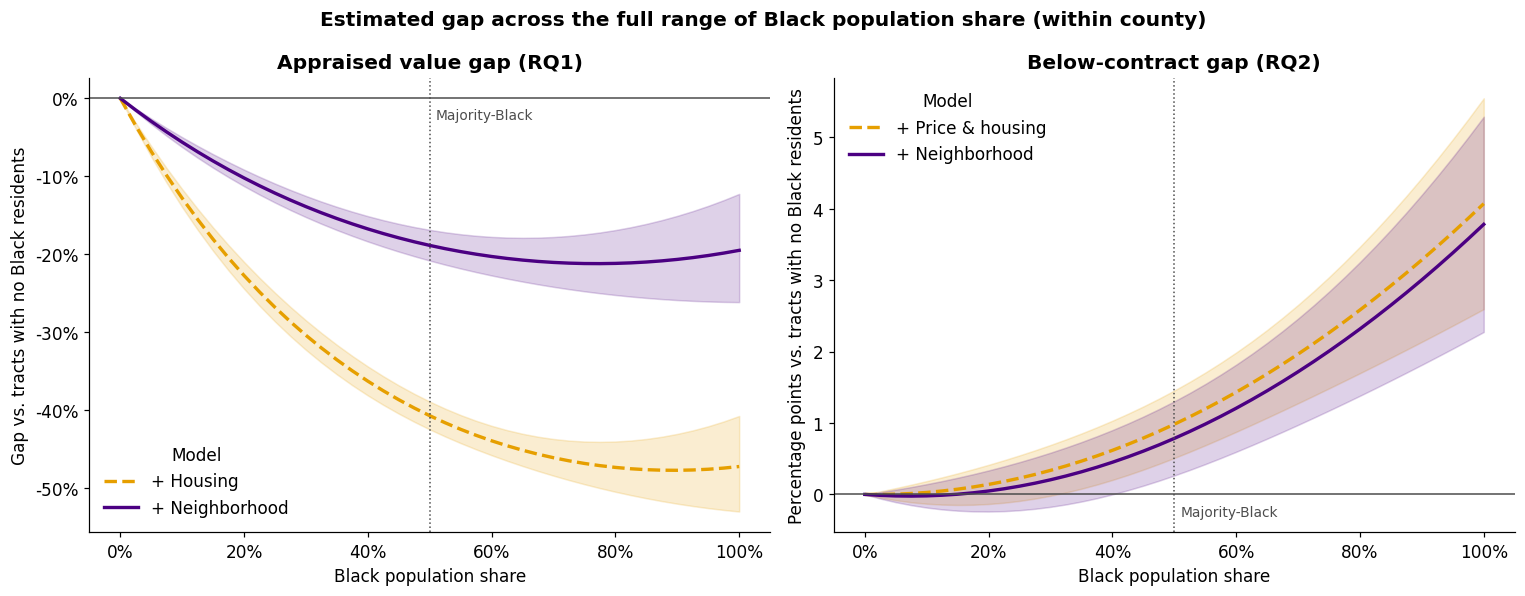

💾 Figure saved: Figures/fig4_continuous_share.png


In [15]:
cont_value_df, _ = prepare_sample(model_df[model_df['has_value_data']], [
    'log_value', 'n_all', 'black_share'])
cont_below_df, _ = prepare_sample(
    model_df[model_df['has_purchase_data']],
    ['share_below_contract', 'log_value', 'n_purchase', 'black_share'])
for sample in (cont_value_df, cont_below_df):
    sample['black_share_sq'] = sample['black_share'] ** 2

print(
    f'🔢 Continuous samples: {len(cont_value_df):,} value tracts (Section 3: {len(rq1_df):,}), '
    f'{len(cont_below_df):,} purchase tracts (Section 3: {len(rq2_df):,})')

share_forms = {
    'Linear': ['black_share'],
    'Quadratic': [
        'black_share',
        'black_share_sq']}


def share_contrast(result, share, quadratic):
    '''Estimated difference between a tract at this Black share and one at 0%.'''
    if share == 0:
        return 0.0, 0.0, 0.0
    expr = f'{share:.4f} * black_share'
    if quadratic:
        expr += f' + {share ** 2:.6f} * black_share_sq'
    test = result.t_test(expr + ' = 0')
    low, high = test.conf_int()[0]
    return float(test.effect[0]), low, high


def continuous_comparison(
        df,
        specs,
        outcome,
        weight_col,
        transform,
        fmt,
        group_gaps):
    '''Compare group, linear, and quadratic estimates at matched contrasts.'''
    rows, fitted = {}, {}
    for stage, (regressors, fe) in specs.items():
        if not fe:
            continue
        controls = [r for r in regressors if r not in group_terms]
        label = 'Black share only' if stage == 'Within county' else stage
        group_row = group_gaps.query(
            'model == @stage and group == "50% or more"').iloc[0]
        column = {
            'Groups: 50% or more vs. under 1%': fmt(
                group_row.gap,
                group_row.ci_low,
                group_row.ci_high)}
        fitted[stage] = {}
        for form, share_terms in share_forms.items():
            result = fit_tract_model(
                df, outcome, share_terms + controls, weight_col)
            fitted[stage][form] = result
            quadratic = form == 'Quadratic'
            est = [transform(v)
                   for v in share_contrast(result, 0.5, quadratic)]
            column[f'{form}: 50% vs. 0%'] = fmt(*est)
            if quadratic:
                est90 = [
                    transform(v) for v in share_contrast(
                        result, 0.9, quadratic)]
                column['Quadratic: 90% vs. 0%'] = fmt(*est90)
        rows[label] = column
    return pd.DataFrame(rows), fitted


value_table, value_fits = continuous_comparison(
    cont_value_df, model_specs, 'log_value', 'n_all',
    lambda b: np.exp(b) - 1, value_fmt, rq1_gaps)
below_table, below_fits = continuous_comparison(
    cont_below_df, rq2_specs, 'share_below_contract', 'n_purchase',
    lambda b: b, point_fmt, rq2_gaps)

print('\n📉 RQ1, appraised value gap: groups vs. continuous share (95% CI):')
display(value_table)
print('\n📈 RQ2, below-contract gap: groups vs. continuous share (95% CI):')
display(below_table)


def gap_curve(result, transform, shares):
    '''Quadratic-model gap and 95% band across a range of Black shares.'''
    points = [share_contrast(result, s, True) for s in shares]
    est, low, high = (np.array([transform(v) for v in series])
                      for series in zip(*points))
    return est, low, high


shares = np.linspace(0, 1, 41)
panels = [
    ('Appraised value gap (RQ1)', value_fits, ['+ Housing', '+ Neighborhood'],
     lambda b: np.exp(b) - 1, PCT_FMT, 'Gap vs. tracts with no Black residents'),
    ('Below-contract gap (RQ2)', below_fits, ['+ Price & housing', '+ Neighborhood'],
     lambda b: b * 100, None, 'Percentage points vs. tracts with no Black residents'),
]
curve_colors = {0: AMBER, 1: PURPLE}

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (title, fits, stages, transform, y_fmt, y_label) in zip(axes, panels):
    for i, stage in enumerate(stages):
        est, low, high = gap_curve(fits[stage]['Quadratic'], transform, shares)
        ax.plot(shares, est, color=curve_colors[i], linewidth=2.2,
                linestyle='-' if i == 1 else '--', label=stage)
        ax.fill_between(shares, low, high, color=curve_colors[i], alpha=0.18)
    ax.axhline(0, color=DARK_GRAY, linewidth=1)
    ax.axvline(0.5, color=DARK_GRAY, linewidth=1, linestyle=':')
    ax.annotate('Majority-Black', (0.5, 0), xytext=(4, -14),
                textcoords='offset points', fontsize=9, color=DARK_GRAY)
    ax.xaxis.set_major_formatter(PCT_FMT)
    if y_fmt is not None:
        ax.yaxis.set_major_formatter(y_fmt)
    ax.set_title(title)
    ax.set_xlabel(DISPLAY_LABELS['black_share'])
    ax.set_ylabel(y_label)
    ax.legend(title='Model', frameon=False)

fig.suptitle(
    'Estimated gap across the full range of Black population share (within county)',
    fontweight='bold')
fig.tight_layout()
fig.savefig(
    FIGURE_DIR /
    'fig4_continuous_share.png',
    dpi=300,
    bbox_inches='tight')
plt.show()
print(f'💾 Figure saved: {FIGURE_DIR.name}/fig4_continuous_share.png')

**Interpretation:** Replacing the five groups with a continuous measure does not change the main findings. For both research questions, the quadratic model's estimate at 50% versus 0% Black share lands close to the group-based estimate at every stage of controls; for appraised value with all controls, the two are 18.9% and 20.7%. The linear model produces smaller estimates because the relationships are not straight lines, and the quadratic model reveals their shapes.

The two research questions follow opposite patterns. For appraised value, the gap builds quickly and then levels off: with all controls, it is 18.9% at 50% Black share and 20.7% at 90%, so most of the measured devaluation is already present by the time a tract is half Black. For below-contract appraisals, the gap builds slowly and then accelerates: with all controls, it is 0.8 percentage points at 50% Black share and 3.0 points at 90%, nearly four times larger. The appraisal gap is therefore concentrated in predominantly Black tracts.

This pattern matches Step 3.5, where same-tract comparable sales were associated with more below-contract appraisals only in majority-Black tracts, and it qualifies the RQ2 estimate from Section 3. The group estimate of 1.4 points averages across all tracts from 50% to 100% Black; in tracts near 90% Black, the fully controlled gap is about twice that size. Figure 4 shows both shapes. In the appraisal panel, the two curves nearly overlap, because neighborhood controls change the below-contract gap very little, and the fully controlled confidence band includes zero until roughly one-third Black share. In the value panel, the fully controlled curve bends slightly upward above 80% Black share; this reflects the shape a quadratic must take and the small number of tracts at that end, where the band is widest, rather than evidence that the gap narrows, so the curve is best read as leveling off.

### **Step 4.4: Compare appraised values with homeowners' own estimates**

Perry et al. (2018) measured home values with the American Community Survey, in which homeowners estimate what their homes would sell for. This analysis uses lender appraisals instead. This step fits the RQ1 models with both measures to see whether they tell the same story. Self-reported values capture all owner-occupied homes rather than only those financed through Fannie Mae or Freddie Mac, but they rely on owners' perceptions rather than professional valuation.

The comparison is built in four columns so each difference has one cause:

1. **Appraised value** on tracts with both measures, weighted by appraisal count, as in Section 3.
2. **Self-reported value** on the same tracts with the same weights. The only change from column 1 is the measure.
3. **Self-reported value** on the same tracts, unweighted. The only change from column 2 is the weighting.
4. **Self-reported value** on all tracts, including those FHFA suppressed. The only change from column 3 is coverage, which tests whether the tracts missing from the appraisal data would change the value gap.

Tracts where the Census top-coded home values at `$2,000,001` are excluded, because their true values are unknown. A second table compares the two measures directly by showing how far owners' estimates sit above or below appraised values in each group.

In [16]:
ACS_VALUE_CAP = 2_000_001
acs_ok = model_df['acs_median_home_value'].lt(ACS_VALUE_CAP)
n_top_coded = model_df['acs_median_home_value'].ge(ACS_VALUE_CAP).sum()

matched_df, _ = prepare_sample(
    model_df[model_df['has_value_data'] & acs_ok],
    ['log_value', 'n_all', 'acs_median_home_value'],
)
all_acs_df, _ = prepare_sample(model_df[acs_ok], ['acs_median_home_value'])
for sample in (matched_df, all_acs_df):
    sample['log_acs_value'] = np.log(sample['acs_median_home_value'])
    sample['unit_weight'] = 1.0

print(f'🏠 Top-coded ACS values excluded: {n_top_coded:,} tracts')
print(f'🔗 Matched sample: {len(matched_df):,} tracts with both measures')
print(
    f'🌐 All-tract sample: {len(all_acs_df):,} tracts with self-reported values '
    f'({len(all_acs_df) - len(matched_df):,} more than the matched sample)')

measure_variants = {
    'Appraised (weighted)': (matched_df, 'log_value', 'n_all'),
    'Self-reported (weighted)': (matched_df, 'log_acs_value', 'n_all'),
    'Self-reported (unweighted)': (matched_df, 'log_acs_value', 'unit_weight'),
    'Self-reported, all tracts': (all_acs_df, 'log_acs_value', 'unit_weight'),
}
measure_rows = {}
for stage, (regressors, fe) in model_specs.items():
    measure_rows[stage] = {
        name: value_fmt(*majority_gap(
            fit_tract_model(df, outcome, regressors, weight, county_fe=fe),
            lambda b: np.exp(b) - 1))
        for name, (df, outcome, weight) in measure_variants.items()
    }

print('\n📉 Majority-Black value gap by measure (95% CI):')
display(pd.DataFrame(measure_rows).T)

matched_df['acs_vs_appraisal'] = np.exp(
    matched_df['log_acs_value'] - matched_df['log_value']) - 1
perception = (
    matched_df.groupby('black_share_group', observed=True)['acs_vs_appraisal']
    .median()
    .rename('Self-reported vs. appraised (median)')
    .to_frame()
    .rename_axis(DISPLAY_LABELS['black_share_group'])
)
correlation = matched_df[['log_value', 'log_acs_value']].corr().iloc[0, 1]
print(
    f'\n🔁 Correlation between the two measures (log scale): {correlation:.2f}')
print('🪞 How owners\' estimates compare with appraisals, by group:')
display(perception.style.format('{:+.1%}'))

🏠 Top-coded ACS values excluded: 531 tracts
🔗 Matched sample: 73,962 tracts with both measures
🌐 All-tract sample: 79,971 tracts with self-reported values (6,009 more than the matched sample)

📉 Majority-Black value gap by measure (95% CI):


,Appraised (weighted),Self-reported (weighted),Self-reported (unweighted),"Self-reported, all tracts"
Raw (national),-42.2% (-48.1% to -35.7%),-43.6% (-50.2% to -36.3%),-44.0% (-50.4% to -36.9%),-46.9% (-54.0% to -38.7%)
Within county,-51.6% (-54.4% to -48.7%),-52.8% (-55.5% to -49.9%),-53.1% (-55.8% to -50.3%),-53.8% (-56.9% to -50.5%)
+ Housing,-44.2% (-47.0% to -41.3%),-44.0% (-46.9% to -40.9%),-44.6% (-47.4% to -41.6%),-45.5% (-48.3% to -42.5%)
+ Neighborhood,-20.9% (-23.9% to -17.9%),-20.4% (-23.4% to -17.3%),-21.8% (-24.5% to -19.1%),-22.8% (-25.5% to -20.0%)



🔁 Correlation between the two measures (log scale): 0.93
🪞 How owners' estimates compare with appraisals, by group:


,Self-reported vs. appraised (median)
Black population share,
Under 1%,-13.9%
1% to 10%,-11.1%
10% to 25%,-12.2%
25% to 50%,-14.9%
50% or more,-16.8%


**Interpretation:** Lender appraisals and homeowners' own estimates produce nearly identical value gaps. On the same 73,962 tracts with the same weights, the fully controlled majority-Black gap is 20.9% using appraised values and 20.4% using self-reported values, and the two measures are closely correlated (0.93 on the log scale). The devaluation found in RQ1 therefore does not depend on the measure, and this analysis and Perry et al. (2018) appear to capture the same underlying gap.

Neither weighting nor coverage changes that conclusion. Removing the appraisal-count weights moves the fully controlled gap from 20.4% to 21.8%. Adding the 6,009 tracts that lack usable appraisal data, mostly because FHFA suppressed them for low volume, moves it to 22.8%. The tracts missing from the appraisal data therefore show, if anything, slightly more devaluation than those included, which suggests the coverage gap identified in Step 1.3 makes the RQ1 estimates somewhat conservative rather than inflated.

Self-reported values sit 11% to 17% below appraised values in every group. This level difference likely reflects measurement timing rather than owners' perceptions: the ACS averages estimates across 2019 to 2023 and adjusts them for general inflation, while appraised values here were adjusted to 2023 home price levels, which rose considerably faster. Appraisals also cover only homes being sold or refinanced. Because every group shares these differences, the comparison across groups remains informative: owners' estimates fall furthest below appraisals in majority-Black tracts (16.8%, versus 13.9% in tracts under 1% Black). This modest difference may suggest that owners in majority-Black tracts value their homes more conservatively relative to the market, but it is small and is noted here rather than interpreted further.

### **Step 4.5: Test whether missing purchase data biases RQ2**

Step 1.3 found that purchase data exists for only 50.2% of majority-Black tracts, compared with 83.7% of tracts under 1% Black. RQ2's estimates come from the tracts that are visible, so if the missing tracts differ in ways related to below-contract appraisals, the estimates could be biased. Unlike RQ1, there is no self-reported version of the below-contract rate to fill the gap, so this step uses two indirect tests.

**Comparing the two halves.** The first table compares tracts with and without purchase data on everything the Census reports for both, separately for majority-Black tracts and tracts under 1% Black. Step 3.3 found that lower-valued tracts see more below-contract appraisals, so the direction of any value difference indicates the likely direction of bias.

**Reweighting the visible tracts.** The second test estimates each tract's probability of having purchase data from its characteristics and state, then refits the RQ2 models giving more weight to visible tracts that resemble the ones missing. This inverse probability weighting adjusts for differences in measured characteristics. It cannot adjust for differences the data does not capture, so it tests sensitivity rather than removing all possible bias. Probabilities are floored at 5% so a handful of unusual tracts cannot dominate the weights.

In [17]:
PROPENSITY_FLOOR = 0.05

coverage_df, _ = prepare_sample(
    model_df,
    ['GEOID', 'has_purchase_data', 'acs_median_home_value', 'pop_total', 'black_share',
     'median_hh_income'],
)
coverage_df = coverage_df.assign(
    covered=coverage_df['has_purchase_data'].astype(float),
    log_acs_value=np.log(coverage_df['acs_median_home_value']),
    log_pop=np.log(coverage_df['pop_total']),
    state_fips=coverage_df['county_fips'].str[:2],
)

# Test 1: do covered and missing tracts differ?
compare_cols = [
    'acs_median_home_value', 'median_hh_income', 'owner_share', 'black_share',
    'median_rooms', 'median_year_built', 'vacancy_rate', 'pop_total',
]
compare_labels = {**DISPLAY_LABELS, 'pop_total': 'Population'}
comparison = {}
for group in ['50% or more', 'Under 1%']:
    in_group = coverage_df[coverage_df['black_share_group'] == group]
    for status, label in [(1.0, 'with purchase data'), (0.0, 'missing')]:
        subset = in_group[in_group['covered'] == status]
        comparison[f'{group}, {label} ({len(subset):,})'] = subset[compare_cols].median(
        )
comparison_table = pd.DataFrame(comparison).rename(index=compare_labels)

row_formats = {
    compare_labels['acs_median_home_value']: '${:,.0f}',
    compare_labels['median_hh_income']: '${:,.0f}',
    compare_labels['owner_share']: '{:.1%}',
    compare_labels['black_share']: '{:.1%}',
    compare_labels['median_rooms']: '{:.1f}',
    compare_labels['median_year_built']: '{:.0f}',
    compare_labels['vacancy_rate']: '{:.1%}',
    compare_labels['pop_total']: '{:,.0f}',
}
formatted = comparison_table.copy().astype(object)
for row, fmt in row_formats.items():
    formatted.loc[row] = [fmt.format(v) for v in comparison_table.loc[row]]
print('🔍 Tracts with and without purchase data (medians):')
display(formatted)

# Test 2: reweight visible tracts to stand in for missing ones
propensity_terms = (group_terms +
                    HOUSING_CONTROLS +
                    NEIGHBORHOOD_CONTROLS +
                    ['log_acs_value', 'log_pop'])
propensity_formula = 'covered ~ ' + \
    ' + '.join(propensity_terms) + ' + C(state_fips)'
propensity_model = smf.glm(
    propensity_formula, data=coverage_df, family=sm.families.Binomial()).fit()
coverage_df['p_covered'] = propensity_model.predict(coverage_df)
n_floored = (coverage_df['p_covered'] < PROPENSITY_FLOOR).sum()
coverage_df['p_covered'] = coverage_df['p_covered'].clip(
    lower=PROPENSITY_FLOOR)

ipw_df, _ = prepare_sample(
    model_df[model_df['has_purchase_data']],
    ['GEOID', 'share_below_contract', 'log_value', 'n_purchase'])
ipw_df = ipw_df.merge(
    coverage_df[['GEOID', 'p_covered']], on='GEOID', how='inner')
ipw_df['ipw_weight'] = ipw_df['n_purchase'] / ipw_df['p_covered']

print(f'\n⚖️  Coverage model fit on {len(coverage_df):,} tracts; '
      f'{n_floored:,} probabilities floored at {PROPENSITY_FLOOR:.0%}')
print(
    f'🧾 Reweighted RQ2 sample: {len(ipw_df):,} tracts (Section 3: {len(rq2_df):,})')

ipw_rows = {}
for stage, (regressors, fe) in rq2_specs.items():
    ipw_rows[stage] = {
        name: point_fmt(
            *
            majority_gap(
                fit_tract_model(
                    ipw_df,
                    'share_below_contract',
                    regressors,
                    weight,
                    county_fe=fe),
                lambda b: b)) for name,
        weight in [
            ('Standard weights',
             'n_purchase'),
            ('Coverage-reweighted',
             'ipw_weight')]}
print('\n📈 Majority-Black below-contract gap, standard vs. coverage-reweighted (95% CI):')
display(pd.DataFrame(ipw_rows).T)

🔍 Tracts with and without purchase data (medians):


,"50% or more, with purchase data (3,120)","50% or more, missing (2,723)","Under 1%, with purchase data (19,426)","Under 1%, missing (3,592)"
ACS self-reported median home value,"$194,700","$102,400","$310,950","$157,650"
Median household income,"$55,622","$37,144","$84,063","$59,240"
Owner-occupied share,56.6%,40.6%,81.9%,70.9%
Black population share,68.3%,75.3%,0.2%,0.0%
Median rooms,5.6,5.1,6.0,5.2
Median year built,1969,1962,1979,1975
Vacancy rate,9.1%,17.6%,7.4%,13.1%
Population,"3,872","2,334","3,794","2,508"



⚖️  Coverage model fit on 80,502 tracts; 1,732 probabilities floored at 5%
🧾 Reweighted RQ2 sample: 64,881 tracts (Section 3: 65,049)

📈 Majority-Black below-contract gap, standard vs. coverage-reweighted (95% CI):


,Standard weights,Coverage-reweighted
Raw (national),+6.5 pts (+5.0 to +7.9),+6.2 pts (+4.7 to +7.6)
Within county,+5.3 pts (+4.4 to +6.1),+5.4 pts (+4.6 to +6.2)
+ Price & housing,+1.7 pts (+1.0 to +2.4),+1.7 pts (+1.0 to +2.4)
+ Neighborhood,+1.4 pts (+0.7 to +2.2),+1.5 pts (+0.8 to +2.3)


**Interpretation:** The majority-Black tracts missing from the purchase data differ substantially from those included. Compared with majority-Black tracts that have purchase data, the missing tracts have median self-reported home values about 47% lower (`$102,400` versus `$194,700`), median household incomes about a third lower, homeownership 16 percentage points lower, nearly twice the vacancy rate (17.6% versus 9.1%), and a higher Black population share (75.3% versus 68.3%).

Part of this pattern is general to low-volume tracts: among tracts under 1% Black, those missing purchase data are also about 49% lower in value. What distinguishes the missing majority-Black tracts is their absolute level of economic distress, which exceeds that of missing tracts in any other group. Two earlier findings indicate the direction this likely pushes the estimates. Lower-valued tracts see more below-contract appraisals (Step 3.3), and the appraisal gap grows with Black population share (Step 4.3). Because the missing majority-Black tracts are both lower-valued and more heavily Black, their below-contract rates, if observed, would likely be higher than those of the included tracts.

Reweighting the included tracts to resemble the full set of tracts changes the fully controlled gap only from 1.4 to 1.5 percentage points, and every estimate in the table moves by 0.3 points or less. Differences in measured characteristics therefore do not distort the RQ2 results. Reweighting cannot fully represent the most distressed missing tracts, however: 1,732 tracts had predicted probabilities low enough to require the 5% floor, meaning few included tracts closely resemble them.

Taken together, the RQ2 estimates are robust for the kinds of tracts the data can observe, and any remaining bias from the coverage gap most likely leads them to understate the appraisal gap rather than overstate it. The tracts least visible in the data are also those where the appraisal gap would likely be largest.

### **Step 4.6: Test whether the comparable-sales finding depends on controls**

Step 3.5 found that a larger share of same-tract comparable sales goes with more below-contract appraisals in majority-Black tracts but not elsewhere. Because the first prediction in that step changed depending on which controls were included, this step refits the same interaction model under four specifications: Black share alone, with price and housing controls, with all controls as in Step 3.5, and with all controls plus the average distance to comparable sales. The last specification addresses the most direct alternative explanation, that reliance on same-tract sales simply reflects how dense and compact a market is.

For each specification, the table reports the effect of a 10-point increase in same-tract comparables in majority-Black tracts and in all other tracts, along with the difference between them. The difference is the direct test of whether the practice carries different consequences in majority-Black tracts.

In [18]:
p2_df, _ = prepare_sample(
    model_df[model_df['has_purchase_data']],
    ['share_below_contract', 'log_value', 'n_purchase', 'comps_same_tract', 'comps_distance'],
)
p2_mean = np.average(p2_df['comps_same_tract'], weights=p2_df['n_purchase'])
p2_df['comps_c'] = p2_df['comps_same_tract'] - p2_mean
p2_df['comps_x_majority'] = p2_df['comps_c'] * p2_df['grp_50_plus']

interaction_terms = ['comps_c', 'comps_x_majority']
p2_specs = {
    'Black share only': group_terms + interaction_terms,
    '+ Price & housing': group_terms + ['log_value'] + HOUSING_CONTROLS + interaction_terms,
    '+ Neighborhood (Step 3.5)': full_controls + interaction_terms,
    '+ Comparable distance': full_controls + ['comps_distance'] + interaction_terms,
}

print(f'🧾 Sample: {len(p2_df):,} tracts (Step 3.5: {len(mech_df):,})')

p2_rows = {
    'Comps effect, majority-Black tracts': {},
    'Comps effect, other tracts': {},
    'Difference (majority-Black minus other)': {},
}
n_hold = 0
for name, regressors in p2_specs.items():
    result = fit_tract_model(
        p2_df,
        'share_below_contract',
        regressors,
        'n_purchase')

    combined = result.t_test('comps_c + comps_x_majority = 0')
    maj_est = float(combined.effect[0]) * 10
    maj_low, maj_high = (combined.conf_int()[0] * 10).tolist()
    diff = coef_summary(result, 'comps_x_majority', 10)

    p2_rows['Comps effect, majority-Black tracts'][name] = fmt_interval(
        maj_est, maj_low, maj_high, 'pts', 2)
    p2_rows['Comps effect, other tracts'][name] = fmt_interval(
        *coef_summary(result, 'comps_c', 10), 'pts', 2)
    p2_rows['Difference (majority-Black minus other)'][name] = fmt_interval(*diff, 'pts', 2)

    if maj_low > 0 and diff[1] > 0:
        n_hold += 1

print('\n📈 Effect of +10 pts same-tract comparables on the below-contract rate (95% CI):')
display(pd.DataFrame(p2_rows).T.reindex(columns=list(p2_specs)))

verdict = '✅' if n_hold == len(p2_specs) else '⚠️'
print(
    f'\n{verdict} Majority-Black effect positive and larger than elsewhere in '
    f'{n_hold} of {len(p2_specs)} specifications')

🧾 Sample: 65,049 tracts (Step 3.5: 65,049)

📈 Effect of +10 pts same-tract comparables on the below-contract rate (95% CI):


,Black share only,+ Price & housing,+ Neighborhood (Step 3.5),+ Comparable distance
"Comps effect, majority-Black tracts",+0.74 pts (+0.47 to +1.02),+0.74 pts (+0.48 to +0.99),+0.80 pts (+0.55 to +1.05),+0.78 pts (+0.53 to +1.03)
"Comps effect, other tracts",-0.09 pts (-0.20 to +0.03),-0.06 pts (-0.14 to +0.02),-0.02 pts (-0.09 to +0.05),-0.06 pts (-0.13 to +0.01)
Difference (majority-Black minus other),+0.83 pts (+0.55 to +1.11),+0.79 pts (+0.53 to +1.06),+0.82 pts (+0.56 to +1.08),+0.84 pts (+0.58 to +1.10)



✅ Majority-Black effect positive and larger than elsewhere in 4 of 4 specifications


**Interpretation:** The comparable-sales finding from Step 3.5 holds in every specification. In majority-Black tracts, a 10-point increase in same-tract comparables goes with a below-contract rate 0.74 to 0.80 percentage points higher, and every confidence interval excludes zero. In all other tracts, the same increase has no measurable effect, with estimates between -0.09 and -0.02 points and intervals that include zero. The difference between the two, the direct test of whether the practice carries different consequences in majority-Black tracts, ranges from 0.79 to 0.84 points and is statistically clear in all four specifications.

Adding the average distance to comparable sales changes the majority-Black effect from 0.80 to 0.78 points. Reliance on same-tract sales is therefore not simply a stand-in for denser or more compact markets. Unlike the first prediction in Step 3.5, which depended on the choice of controls, this result does not depend on any specification tested here, making it the most stable finding in the analysis.

## **5. Expected Value Model**

### **Step 5.1: Train and validate a model of expected appraised value**

Sections 3 and 4 measured the valuation gap with regression, which assumes each characteristic affects value in a fixed, additive way. This section uses gradient boosting (LightGBM), which learns nonlinear relationships and interactions directly from the data, such as rooms mattering more in some markets than others. The model predicts each tract's appraised value from its characteristics with every race and ethnicity measure excluded. Step 5.3 then compares actual values with these expectations by Black population share, a third, methodologically independent test of RQ1.

**Features.** Two feature sets mirror the regression models: housing characteristics plus local market context, and the same with neighborhood conditions added. Market context comes from two features. The first is the appraisal-weighted average value of the other tracts in the same county, calculated without the tract itself so the model never sees the value it is predicting; this lets the model compare each tract with its local market. The second is the logarithm of tract population.

**Validation.** The model is validated with five-fold cross-validation grouped by state: each fold holds out entire states, so every prediction is made by a model that never saw any tract from that state. This is stricter than random splits, because nearby tracts share conditions that would otherwise let the model look more accurate than it is. Every tract's prediction comes from the fold in which it was held out, so the gaps in Step 5.3 are never measured against a model that saw them. Performance is compared with a simple baseline that predicts each tract's value as its county average.

In [19]:
def add_market_context(df):
    '''Add the appraisal-weighted county average log value, excluding each tract itself.'''
    w = df['n_all']
    county = df['county_fips']
    sum_w = w.groupby(county).transform('sum')
    sum_wy = (w * df['log_value']).groupby(county).transform('sum')
    return df.assign(
        county_value_loo=(sum_wy - w * df['log_value']) / (sum_w - w),
        log_pop=np.log(df['pop_total']),
        state_fips=df['county_fips'].str[:2],
    )


def score(y_true, y_pred):
    '''R², RMSE, and MAE on the log scale, plus MAE as a typical percent error.'''
    mae = mean_absolute_error(y_true, y_pred)
    return {
        'R²': r2_score(y_true, y_pred),
        'RMSE (log)': np.sqrt(mean_squared_error(y_true, y_pred)),
        'MAE (log)': mae,
        'Typical error': np.exp(mae) - 1,
    }


def cross_validate(df, features):
    '''State-grouped cross-validation returning out-of-fold predictions and fold scores.'''
    oof = np.zeros(len(df))
    fold_scores = []
    splitter = GroupKFold(n_splits=N_FOLDS)
    for fold, (train_idx, test_idx) in enumerate(
            splitter.split(df, groups=df['state_fips']), 1):
        train, test = df.iloc[train_idx], df.iloc[test_idx]
        model = lgb.LGBMRegressor(**LGB_PARAMS)
        model.fit(
            train[features],
            train['log_value'],
            sample_weight=train['n_all'])
        oof[test_idx] = model.predict(test[features])
        fold_scores.append({
            'Fold': fold,
            'States held out': test['state_fips'].nunique(),
            'Tracts': len(test),
            **score(test['log_value'], oof[test_idx]),
        })
    return oof, pd.DataFrame(fold_scores)


ml_df, _ = prepare_sample(model_df[model_df['has_value_data']], [
    'GEOID', 'log_value', 'n_all', 'pop_total', 'black_share'])
ml_df = add_market_context(ml_df)
print(
    f'🤖 Model sample: {len(ml_df):,} tracts in {ml_df["state_fips"].nunique():,} '
    f'state-level areas; race and ethnicity measures excluded from every feature set')

results = {
    'County average (baseline)': score(
        ml_df['log_value'],
        ml_df['county_value_loo'])}
fold_tables = {}
final_models = {}
for name, features in ML_FEATURE_SETS.items():
    oof, folds = cross_validate(ml_df, features)
    ml_df[f'oof_{name}'] = oof
    results[name] = score(ml_df['log_value'], oof)
    fold_tables[name] = folds
    final_models[name] = lgb.LGBMRegressor(**LGB_PARAMS).fit(
        ml_df[features], ml_df['log_value'], sample_weight=ml_df['n_all'])
    print(f'✅ {name}: cross-validated and refit on all tracts')

print('\n📏 Out-of-fold performance (every prediction made on unseen states):')
display(
    pd.DataFrame(results).T.style.format(
        {
            'R²': '{:.3f}',
            'RMSE (log)': '{:.3f}',
            'MAE (log)': '{:.3f}',
            'Typical error': '{:.1%}',
        }))

full_name = 'Housing + market + neighborhood'
print(f'\n🧩 Fold-by-fold stability, {full_name}:')
display(fold_tables[full_name].style.format({
    'Tracts': '{:,}', 'R²': '{:.3f}', 'RMSE (log)': '{:.3f}', 'MAE (log)': '{:.3f}',
    'Typical error': '{:.1%}',
}).hide(axis='index'))

🤖 Model sample: 74,802 tracts in 51 state-level areas; race and ethnicity measures excluded from every feature set
✅ Housing + market: cross-validated and refit on all tracts
✅ Housing + market + neighborhood: cross-validated and refit on all tracts

📏 Out-of-fold performance (every prediction made on unseen states):


,R²,RMSE (log),MAE (log),Typical error
County average (baseline),0.638,0.377,0.291,33.8%
Housing + market,0.721,0.331,0.244,27.6%
Housing + market + neighborhood,0.851,0.242,0.182,19.9%



🧩 Fold-by-fold stability, Housing + market + neighborhood:


Fold,States held out,Tracts,R²,RMSE (log),MAE (log),Typical error
1,9,"14,984",0.829,0.281,0.212,23.7%
2,10,"14,978",0.761,0.236,0.180,19.7%
3,10,"14,881",0.832,0.243,0.178,19.5%
4,11,"14,995",0.856,0.235,0.179,19.6%
5,11,"14,964",0.855,0.211,0.160,17.3%


**Interpretation:** The expected-value model predicts appraised values well for states it never saw during training. With housing, market, and neighborhood features, it explains 85.1% of the variation in log appraised value across held-out states, with a typical prediction error of 19.9%. A baseline that predicts each tract's value as its county average explains 63.8%, with a typical error of 33.8%, so the model reduces typical error by about 40%.

Neighborhood conditions contribute the largest improvement. Housing and market features alone raise the explained variation from 63.8% to 72.1%, and adding neighborhood conditions raises it to 85.1%. This matches the regression results in Step 3.1, where neighborhood controls also accounted for the largest share of variation, and it supports reading the two feature sets as a range in Step 5.3, just as in the regression.

Performance is stable across folds, with explained variation between 76.1% and 85.6%. The second fold's lower value comes with prediction errors similar to the others, which suggests its held-out states have less variation in value to explain rather than worse predictions. The first fold has the largest errors (23.7%), plausibly because it holds out higher-cost markets.

A typical error near 20% means the gap estimated for any single tract carries substantial uncertainty. Comparisons across groups of tracts average much of this error away, but tract-level results, including those prepared for QRoots, should be presented as ranges rather than precise values.

### **Step 5.2: Explain the model's expected values with SHAP**

SHAP (SHapley Additive exPlanations) divides each tract's predicted value into contributions from each feature, measured relative to the average prediction. A positive contribution means that feature raised the tract's expected value, and a negative one means it lowered it. Because the model predicts log value, a contribution of 0.10 corresponds to roughly 10% higher expected value. SHAP values are computed with LightGBM's built-in implementation of the TreeSHAP algorithm, which produces the same values as the SHAP library's tree explainer in a fraction of the time.

The figure shows contributions for a random sample of 5,000 tracts. Each point is one tract, its horizontal position is the feature's contribution, and its color shows whether the tract's value for that feature was low (blue) or high (amber). Features are ordered by average importance.

**Proxy check.** The model never sees race or ethnicity, but several of its features are correlated with Black population share (Step 2.3), so racial patterns can still enter its predictions indirectly. To measure this, SHAP contributions are averaged for majority-Black tracts and for tracts under 1% Black, and the difference shows how much each feature lowers or raises expected values in majority-Black tracts relative to the reference group. This identifies which features carry racial patterns into the model's expectations, which matters for interpreting the gaps in Step 5.3 and for any use of the model in QRoots.

🔬 SHAP values computed for all 74,802 tracts


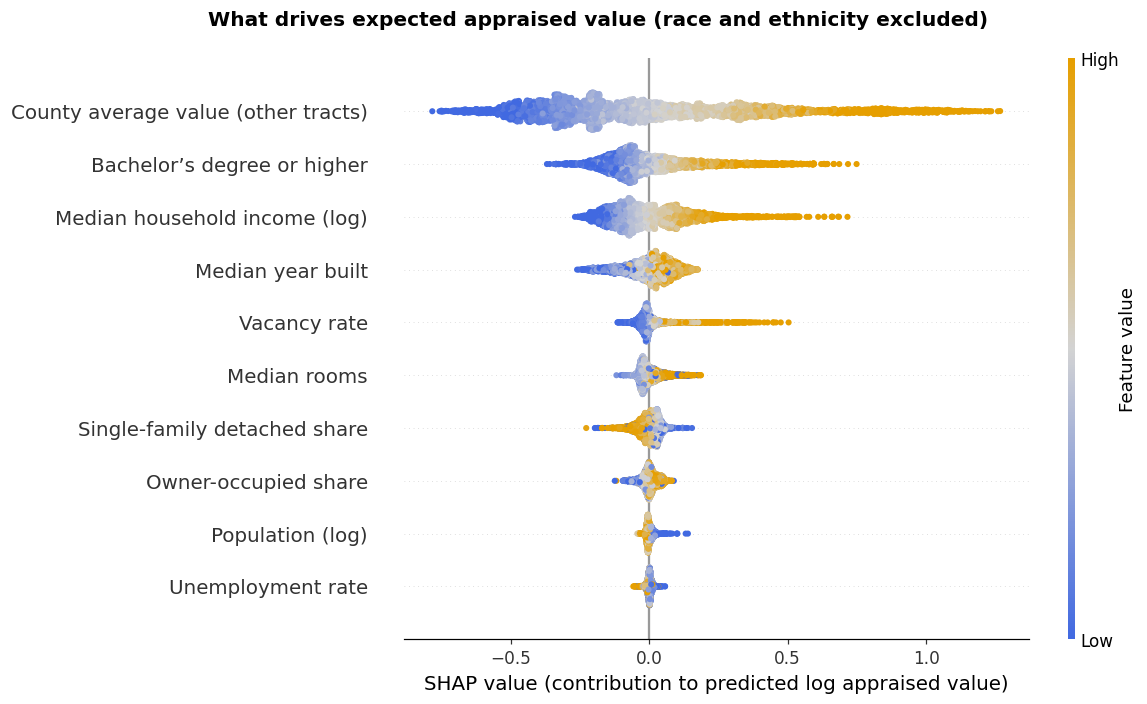

📊 Feature importance (mean absolute contribution):


,Mean |SHAP|,Share of total
County average value (other tracts),0.325,44.2%
Bachelor’s degree or higher,0.121,16.5%
Median household income (log),0.106,14.4%
Median year built,0.061,8.3%
Vacancy rate,0.032,4.4%
Single-family detached share,0.028,3.8%
Median rooms,0.027,3.7%
Owner-occupied share,0.020,2.7%
Population (log),0.009,1.2%
Unemployment rate,0.006,0.8%



🧭 Proxy check: how each feature shifts expected value in majority-Black tracts relative to tracts under 1% Black:


,Log-point contribution,Approximate effect
Median household income (log),-0.137,-12.8%
County average value (other tracts),-0.107,-10.1%
Bachelor’s degree or higher,-0.101,-9.6%
Median year built,-0.051,-4.9%
Owner-occupied share,-0.036,-3.5%
Median rooms,-0.014,-1.4%
Vacancy rate,-0.013,-1.3%
Unemployment rate,-0.009,-0.9%
Population (log),-0.001,-0.1%
Single-family detached share,+0.003,+0.3%



🎯 Combined: features lower expected value in majority-Black tracts by -37.2%; neighborhood conditions alone account for -25.6%
💾 Figure saved: Figures/fig5_shap_summary.png


In [20]:
full_features = ML_FEATURE_SETS[full_name]
contributions = final_models[full_name].predict(
    ml_df[full_features], pred_contrib=True, num_threads=1)
shap_values = contributions[:, :-1]
shap_df = pd.DataFrame(
    shap_values,
    columns=[
        DISPLAY_LABELS[f] for f in full_features],
    index=ml_df.index)
print(f'🔬 SHAP values computed for all {len(ml_df):,} tracts')

plot_idx = ml_df.sample(n=5_000, random_state=RANDOM_STATE).index
shap.summary_plot(
    shap_df.loc[plot_idx].values,
    ml_df.loc[plot_idx, full_features].rename(columns=DISPLAY_LABELS),
    cmap=BRAND_CMAP, show=False, plot_size=(11, 6.5),
)
fig = plt.gcf()
plt.xlabel('SHAP value (contribution to predicted log appraised value)')
fig.suptitle(
    'What drives expected appraised value (race and ethnicity excluded)',
    fontweight='bold')
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'fig5_shap_summary.png', dpi=300, bbox_inches='tight')
plt.show()

importance = shap_df.abs().mean().sort_values(ascending=False)
importance_table = pd.DataFrame({
    'Mean |SHAP|': importance,
    'Share of total': importance / importance.sum(),
})
print('📊 Feature importance (mean absolute contribution):')
display(importance_table.style.format(
    {'Mean |SHAP|': '{:.3f}', 'Share of total': '{:.1%}'}))

groups = ml_df['black_share_group']
contrast = shap_df[groups == '50% or more'].mean(
) - shap_df[groups == 'Under 1%'].mean()
proxy_table = pd.DataFrame({
    'Log-point contribution': contrast,
    'Approximate effect': np.exp(contrast) - 1,
}).sort_values('Log-point contribution')
print(
    '\n🧭 Proxy check: how each feature shifts expected value in majority-Black tracts '
    'relative to tracts under 1% Black:')
display(proxy_table.style.format(
    {'Log-point contribution': '{:+.3f}', 'Approximate effect': '{:+.1%}'}))

total_shift = np.exp(contrast.sum()) - 1
neighborhood_labels = [DISPLAY_LABELS[c] for c in NEIGHBORHOOD_CONTROLS]
neighborhood_shift = np.exp(contrast[neighborhood_labels].sum()) - 1
print(
    f'\n🎯 Combined: features lower expected value in majority-Black tracts by {total_shift:+.1%}; '
    f'neighborhood conditions alone account for {neighborhood_shift:+.1%}')
print(f'💾 Figure saved: {FIGURE_DIR.name}/fig5_shap_summary.png')

**Interpretation:** Local market context is the strongest driver of expected value, accounting for 44.2% of the model's total feature contribution, followed by education (16.5%) and income (14.4%). Housing characteristics contribute less: median year built accounts for 8.3%, and rooms and single-family share about 4% each. Two patterns in the figure run against intuition and reflect the data rather than a general rule. High vacancy raises expected value, likely because the Census counts seasonal and vacation homes as vacant, so high-vacancy tracts include resort and second-home areas. A high share of single-family detached homes slightly lowers expected value once county prices and income are known, likely because such tracts tend to be suburban or rural rather than high-cost urban cores.

The proxy check shows that excluding race from the model does not keep racial patterns out of its predictions. The model expects majority-Black tracts to be appraised 37.2% below tracts under 1% Black, without ever seeing racial composition. Neighborhood conditions account for 25.6% of that difference, led by income (12.8%) and education (9.6%), consistent with the correlations in Step 2.3. The county market average contributes another 10.1%, which may partly reflect the lower values of nearby majority-Black tracts carrying into the measure of local market context.

This has practical implications beyond this analysis. Valuation models that exclude race but rely on neighborhood income, education, and nearby sale prices can reproduce much of the racial gap in their expected values, so excluding race from the inputs is not sufficient to prevent racial disparities in the outputs. For this project, it means the model's expected values already absorb most of the gap explained by these features, so the valuation gaps measured in Step 5.3 are, like the fully controlled regression estimates, best read as a lower bound.

### **Step 5.3: Measure the valuation gap and prepare the QRoots table**

For each tract, the valuation gap is the difference between its actual appraised value and the value the Step 5.1 model expected from its housing, market, and neighborhood characteristics. Because every expected value comes from a model that never saw the tract's state, the gaps are measured out of sample. Averaging these gaps by Black population share gives a third test of RQ1 that shares no modeling assumptions with the regressions in Sections 3 and 4. As before, the two feature sets bound the estimate, and Step 5.2 showed that both already absorb much of the racial gap through proxies, so these results are also best read as lower bounds.

**The QRoots table.** The proposal committed to a tract-level valuation gap table for QRoots, along with specific safeguards from its ethical assessment. Those safeguards shape the file directly:

- **No racial or ethnic measures.** The table contains no information about racial composition, so it cannot be used to filter or rank neighborhoods by race, a form of steering prohibited by the Fair Housing Act.
- **Ranges, not single numbers.** Each tract's gap includes an 80% uncertainty range based on how much actual values typically differ from expectations among tracts with a similar number of appraisals, since estimates backed by fewer appraisals are less certain.
- **Neutral labels.** Tracts are labeled "Appraised below expected range," "Within expected range," or "Appraised above expected range," and the first label applies only when the entire range falls below zero. The labels describe a comparison with a model, not a judgment about the neighborhood.
- **Both estimates.** The table includes gaps from both feature sets, so QRoots can present the range of plausible estimates rather than one figure.

In [21]:
resid_cols = {'Housing + market': 'resid_hm', full_name: 'resid_full'}
for name, col in resid_cols.items():
    ml_df[col] = ml_df['log_value'] - ml_df[f'oof_{name}']

# Third test of RQ1: average out-of-sample gap by group
residual_models = {
    name: fit_tract_model(ml_df, col, group_terms, 'n_all', county_fe=False)
    for name, col in resid_cols.items()
}
residual_gaps = gap_table(residual_models, GROUP_DUMMIES)
residual_gaps['display'] = residual_gaps.apply(
    lambda r: f'{r.gap:+.1%} ({r.ci_low:+.1%} to {r.ci_high:+.1%})', axis=1)
print('🤖 Out-of-sample valuation gap vs. tracts under 1% Black (95% CI):')
display(
    residual_gaps.pivot(index='group', columns='model', values='display')
    .reindex(index=list(GROUP_DUMMIES), columns=list(resid_cols))
    .rename_axis(index=DISPLAY_LABELS['black_share_group'], columns=None)
)

regression_majority = rq1_gaps[rq1_gaps['group']
                               == '50% or more'].set_index('model')
ml_majority = residual_gaps[residual_gaps['group']
                            == '50% or more'].set_index('model')
method_comparison = pd.DataFrame({
    'Regression (Section 3)': [
        value_fmt(*regression_majority.loc['+ Housing', ['gap', 'ci_low', 'ci_high']]),
        value_fmt(*regression_majority.loc['+ Neighborhood', ['gap', 'ci_low', 'ci_high']]),
    ],
    'Gradient boosting (Section 5)': [
        value_fmt(*ml_majority.loc['Housing + market', ['gap', 'ci_low', 'ci_high']]),
        value_fmt(*ml_majority.loc[full_name, ['gap', 'ci_low', 'ci_high']]),
    ],
}, index=['Housing-level controls', 'Full controls'])
print('\n🔁 Majority-Black gap, regression vs. machine learning:')
display(method_comparison)

# QRoots export with uncertainty ranges
ml_df['volume_bin'] = pd.qcut(
    ml_df['n_all'],
    5,
    labels=False,
    duplicates='drop')
for col in resid_cols.values():
    noise = ml_df.groupby('volume_bin')[col].transform('std')
    ml_df[f'{col}_low'] = ml_df[col] - INTERVAL_Z * noise
    ml_df[f'{col}_high'] = ml_df[col] + INTERVAL_Z * noise

ml_df['gap_category'] = np.select(
    [ml_df['resid_full_high'] < 0, ml_df['resid_full_low'] > 0],
    ['Appraised below expected range', 'Appraised above expected range'],
    default='Within expected range',
)

qroots_table = pd.DataFrame({
    'GEOID': ml_df['GEOID'],
    'median_appraised_value': np.exp(ml_df['log_value']).round(0),
    'expected_value_full': np.exp(ml_df[f'oof_{full_name}']).round(0),
    'expected_value_housing_market': np.exp(ml_df['oof_Housing + market']).round(0),
    'gap_full': np.exp(ml_df['resid_full']) - 1,
    'gap_full_low': np.exp(ml_df['resid_full_low']) - 1,
    'gap_full_high': np.exp(ml_df['resid_full_high']) - 1,
    'gap_housing_market': np.exp(ml_df['resid_hm']) - 1,
    'gap_category': ml_df['gap_category'],
    'appraisal_count': ml_df['n_all'].astype(int),
    'data_years': f'{pool_start}-{pool_end}',
}).round({'gap_full': 4, 'gap_full_low': 4, 'gap_full_high': 4, 'gap_housing_market': 4})
qroots_table.to_csv(QROOTS_EXPORT, index=False)

print(
    f'\n💾 QRoots table saved: {QROOTS_EXPORT.name} ({len(qroots_table):,} tracts, '
    f'{len(qroots_table.columns)} columns, no racial or ethnic measures)')
print('🏷️  Category distribution, all tracts:')
for label, share in qroots_table['gap_category'].value_counts(
        normalize=True).items():
    print(f'   {label:<32} {share:.1%}')

print('\n🔍 Analysis only (not exported): share of tracts appraised below expected range by group:')
below_by_group = (
    ml_df.assign(below=ml_df['gap_category'] == 'Appraised below expected range')
    .groupby('black_share_group', observed=True)['below'].mean()
)
for group, share in below_by_group.items():
    print(f'   {group:<12} {share:.1%}')

🤖 Out-of-sample valuation gap vs. tracts under 1% Black (95% CI):


,Housing + market,Housing + market + neighborhood
Black population share,,
1% to 10%,-5.0% (-6.5% to -3.4%),-5.0% (-6.2% to -3.9%)
10% to 25%,-14.7% (-16.9% to -12.4%),-10.8% (-12.7% to -9.0%)
25% to 50%,-20.2% (-22.4% to -17.8%),-12.8% (-14.6% to -10.9%)
50% or more,-30.8% (-35.6% to -25.5%),-16.3% (-20.5% to -11.9%)



🔁 Majority-Black gap, regression vs. machine learning:


,Regression (Section 3),Gradient boosting (Section 5)
Housing-level controls,-44.6% (-47.3% to -41.8%),-30.8% (-35.6% to -25.5%)
Full controls,-20.7% (-23.7% to -17.5%),-16.3% (-20.5% to -11.9%)



💾 QRoots table saved: qroots_valuation_gap.csv (74,802 tracts, 11 columns, no racial or ethnic measures)
🏷️  Category distribution, all tracts:
   Within expected range            83.2%
   Appraised above expected range   9.4%
   Appraised below expected range   7.3%

🔍 Analysis only (not exported): share of tracts appraised below expected range by group:
   Under 1%     4.4%
   1% to 10%    6.2%
   10% to 25%   9.5%
   25% to 50%   11.0%
   50% or more  18.2%


**Interpretation:** The gradient boosting model confirms the RQ1 finding with a method that shares no modeling assumptions with the regressions. Measured out of sample, majority-Black tracts are appraised 16.3% below their expected values relative to tracts under 1% Black with all features (95% confidence interval 11.9% to 20.5%), and 30.8% below with housing and market features only. The gap grows with each step up in Black population share under both feature sets, as in every earlier model.

With all controls, the machine learning and regression estimates are statistically consistent (16.3% versus 20.7%, with overlapping intervals). With fewer controls, the machine learning estimate is smaller (30.8% versus 44.6%). This is consistent with Step 5.2: the model's measure of local market context, the average value of other tracts in the county, carries part of the racial pattern from nearby majority-Black tracts, and the more flexible model draws on it more fully. Across both methods, homes in majority-Black tracts are appraised roughly 16% to 45% below comparable homes, with fully controlled estimates between 16% and 21%; because both methods absorb part of the gap through correlated features, these remain lower bounds.

The tract-level categories make the pattern concrete. Using a label that applies only when a tract's entire 80% uncertainty range falls below its expected value, 7.3% of all tracts are appraised below their expected range. That share rises steadily with Black population share, from 4.4% of tracts under 1% Black to 18.2% of majority-Black tracts, about four times as often. Most tracts in every group (83.2% overall) fall within their expected range, which reflects the deliberately cautious standard for the label.

The QRoots table contains these estimates for 74,802 tracts, with both feature-set estimates, 80% uncertainty ranges, appraisal counts, and the data period, and without any racial or ethnic measures. The group breakdown above was computed for this analysis only and is not part of the exported file.

## **Summary**

This notebook tested whether homes in majority-Black and historically redlined census tracts are appraised below comparable homes, using FHFA appraisal statistics for 83,340 tracts in the 50 states and Washington, D.C., pooled across 2019 to 2023 and joined to American Community Survey characteristics and the Historic Redlining Indicator.

**RQ1: Market gap (supported).** Appraised values are lower in tracts with higher Black population shares in every model tested. Compared with tracts under 1% Black in the same county, majority-Black tracts are appraised 52.4% lower before controls, 44.6% lower after housing controls, and 20.7% lower after neighborhood controls (95% confidence interval 17.5% to 23.7%), which contains the 23% reported by Perry et al. (2018). Because neighborhood conditions are themselves shaped by the history this project examines, the housing-level and fully controlled estimates bound the plausible gap rather than one replacing the other.

**RQ2: Appraisal gap (partially supported).** Purchase appraisals in majority-Black tracts fell below the contract price more often (15.7% versus 9.2% before controls), but most of the within-county gap tracks price level. With all controls, a gap of 1.4 percentage points remains (1.16 times the reference rate), concentrated in predominantly Black tracts: about 0.8 points at 50% Black share and 3.0 points at 90%. The appraisal gap appears to follow largely from the market gap rather than arise independently.

**RQ3: Historic legacy (supported for value, not for appraisals).** Each one-grade step toward a 1930s "hazardous" rating predicts values 19.2% lower after accounting for current racial composition, narrowing to 2.8% with all controls. Redlining shows no independent association with below-contract appraisals once price level is included, and it accounts for about 5.5 percentage points of today's majority-Black value gap in HOLC-graded cities.

**Mechanism.** Appraisers in majority-Black tracts do not rely meaningfully more on same-tract comparable sales, so comparable selection does not explain the average appraisal gap. The same practice, however, carries different consequences: in majority-Black tracts, each 10-point increase in same-tract comparables goes with a below-contract rate about 0.8 points higher, while elsewhere it has no measurable effect. This was the most stable result in the analysis, holding under every specification, including controls for the distance to comparables.

**Robustness.** The findings held when the housing market was defined by metro area instead of county, when the appraisal gap was modeled with a fractional logit, when Black population share was measured continuously, and when appraised values were replaced with homeowners' own estimates (20.4% versus 20.9%). Several checks indicated the main estimates are conservative: broader geographic comparisons produced larger appraisal gaps, adding tracts missing from the appraisal data enlarged the value gap, and the majority-Black tracts missing from the purchase data are lower-valued and more heavily Black, which likely leads RQ2 to understate the appraisal gap.

**Machine learning and QRoots.** A gradient boosting model that excludes race predicted values in held-out states with an R² of 0.851 and a typical error of 19.9%. Its out-of-sample valuation gap for majority-Black tracts was 16.3% with all features, consistent with the regression. SHAP analysis showed that the model nonetheless expects majority-Black tracts to be worth 37.2% less through correlated features such as income and education, so excluding race from a valuation model does not keep racial patterns out of its predictions. Majority-Black tracts were about four times as likely as tracts under 1% Black to be appraised below their expected range (18.2% versus 4.4%). The resulting tract-level table for QRoots includes uncertainty ranges and neutral labels and contains no racial or ethnic measures.

**Limitations.** Results are tract-level associations, not evidence of bias in individual appraisals. The data cover only Fannie Mae and Freddie Mac appraisals at the tract level, since FHA appraisals are not published below the county level, and they end before the 2025 changes to federal appraisal policy. Unmeasured neighborhood features such as school quality may account for part of the remaining gap. Spatial dependence was addressed through within-county comparisons and county-clustered standard errors rather than the Moran's I test named in the proposal.

**Implications.** Across methods, homes in majority-Black tracts are appraised roughly 16% to 45% below comparable homes, with fully controlled estimates between 16% and 21%. For lenders and appraisal management companies, the comparable-sales finding points to a specific review practice: examining below-contract appraisals in majority-Black tracts that rely heavily on same-tract sales. For anyone building automated valuation tools, the proxy analysis shows that removing race from the inputs is not sufficient to prevent racial disparities in the outputs.

<hr style="border: 2px solid black; margin-top: 30px;">